# KLAR 500: three quantizers, two FP16--quantized disagreement cohorts

This notebook combines the **same five contribution-recovery conditions** from the three supplied notebook-26 files. It reads saved FP16 and quantized predictions; it does **not** regenerate either baseline, rediscover neurons, or evaluate the concordant cases. It runs recovery only on (A) FP16 correct / quantized wrong and (B) FP16 wrong / quantized correct. The former measures recovery; the latter measures retention and collateral damage. All methods use the same aligned 500 English-anchored facts, FP16 transfer scores, and all-13-language Wikipedia LAPE indices. A missing saved baseline stops the run; if full-layer Wikipedia LAPE is absent, the notebook discovers it from FP16 with per-language caches. Recovery remains on layers 0–7, using the earlier 0–7 LAPE index when available.

The intervention is the original per-token **FP16 contribution replacement**, so it is an oracle experiment rather than a deployable correction. Results are cached separately by method, language, and cohort. The final figure has one panel per method/cohort and one shared legend. Cohort membership is defined **separately for each quantizer**: panels share the same 500-fact universe, but their selected sample IDs and denominators need not be identical.


**Method references and attribution.** The two neuron populations follow the LAPE method of [Tang et al. (ACL 2024)](https://aclanthology.org/2024.acl-long.309/) and the Transfer Neuron method of [Tezuka and Inoue (EMNLP 2025)](https://aclanthology.org/2025.emnlp-main.1618/). The paired same-coordinate comparison across FP16 and quantized models, contribution-profile measurements, and reporting design are extensions developed for this project; the notebook does not claim to rediscover quantizer-specific neuron identities.


In [1]:
import csv, gc, hashlib, json, math, os, random, urllib.parse, urllib.request, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_DATASETS_CACHE', '/root/autodl-tmp/huggingface/datasets')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

torch.set_grad_enabled(False)

# Faster matrix multiplication for the very large score GEMMs on Ampere+ GPUs.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')

## 1. Configuration and saved inputs

In [2]:
FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_SPECS = {
    'GPTQ-INT4': {'kind': 'checkpoint', 'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4')},
    'AWQ-INT4': {'kind': 'checkpoint', 'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4')},
    'BNB-NF4': {'kind': 'bnb_nf4', 'checkpoint': FP16_CHECKPOINT},
}
QUANT_METHODS = ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']
QUANT_MODEL_NAME = QUANT_METHODS[0]  # Set explicitly for each recovery loop.
LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
LANGUAGE_SCRIPT_GROUPS = {
    'ca': 'Latin', 'en': 'Latin', 'es': 'Latin', 'fr': 'Latin', 'hu': 'Latin',
    'nl': 'Latin', 'tr': 'Latin', 'ar': 'Non-Latin', 'el': 'Non-Latin',
    'he': 'Non-Latin', 'ja': 'Non-Latin', 'ko': 'Non-Latin', 'zh': 'Non-Latin',
}
ANALYSIS_ROOT = Path('/root/autodl-tmp/analysis')
FP_SCORE_PATH = (ANALYSIS_ROOT / 'type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin'
                 / 'last_nonpadding_token' / 'paper_scores_fp16_layers_0_7_last_token_fp32_score.pt')
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')
KLAR_OUTPUT_DIR = ANALYSIS_ROOT / 'klar_gptq_english_500facts_template0_12languages_top1_fp16'
FP16_BASELINE_DIR = KLAR_OUTPUT_DIR
QUANT_BASELINE_DIRS = {
    'GPTQ-INT4': KLAR_OUTPUT_DIR,
    'AWQ-INT4': ANALYSIS_ROOT / 'klar_awq_all_aligned_facts_template0_12languages_top1_fp16',
    'BNB-NF4': ANALYSIS_ROOT / 'klar_bnb_english_500facts_template0_12languages_top1_fp16',
}
LAPE_INDEX_CANDIDATES = [
    ANALYSIS_ROOT / 'paper_wikipedia_lape_13languages_fp16_cache'
                  / 'wikipedia_lape_selected_neuron_indices_13languages.csv',
    ANALYSIS_ROOT / 'paper_wikipedia_lape_quantization'
                  / 'layers0_7_full_answer_recovery_gpu_gptq'
                  / 'wikipedia_lape_selected_neuron_indices.csv',
]
OUTPUT_DIR = ANALYSIS_ROOT / 'klar_three_method_lape_transfer_two_discordance_groups'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026
DTYPE = torch.float16
DEVICE_MAP = 'auto'
TRUST_REMOTE_CODE = True
RECOVERY_LAYERS = list(range(8))
# Full-layer LAPE uses the FP16 checkpoint's decoder depth, not recovery depth.
FP16_MODEL_CONFIG = json.loads((FP16_CHECKPOINT / 'config.json').read_text())
LAPE_ANALYSIS_LAYERS = list(range(int(FP16_MODEL_CONFIG['num_hidden_layers'])))
if LAPE_ANALYSIS_LAYERS[:len(RECOVERY_LAYERS)] != RECOVERY_LAYERS:
    raise RuntimeError('Recovery layers are not the prefix of the FP16 model layers.')
WIKI_LOCAL_ROOT = Path('/root/autodl-tmp/data/wikipedia')
LAPE_FULL_DIR = ANALYSIS_ROOT / 'paper_wikipedia_lape_13languages_fp16_full_layers'
LAPE_FULL_DIR.mkdir(parents=True, exist_ok=True)
LAPE_FULL_INDEX_PATH = LAPE_FULL_DIR / 'wikipedia_lape_selected_neuron_indices_13languages_full_layers.csv'
LAPE_TOKENS_PER_LANGUAGE = 1_000_000
LAPE_SEQUENCE_LENGTH = 512
LAPE_BATCH_SIZE = 4
LAPE_BOTTOM_RATE = 0.10
LAPE_ACTIVITY_QUANTILE = 0.95
# Full-layer discovery is costly. Per-language activation caches make it resumable.
AUTO_DISCOVER_FULL_LAYER_LAPE = True
TOP_RATE = 0.01
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True
KLAR_MAX_LENGTH = 1024
KLAR_GENERATION_MAX_NEW_TOKENS = 8
KLAR_Q_FORWARD_BATCH_SIZE = 12
KLAR_GENERATION_CONDITIONS_PER_BATCH = 4
KLAR_SAMPLE_TOTAL = 500
KLAR_SAMPLE_SEED = SEED + 50500
RECOVERY_CONDITION_NAMES = [
    'lape', 'transfer', 'lape_plus_transfer',
    'all_language_lape_plus_transfer', 'random_largest_matched',
]
COHORTS = ['fp_correct_q_wrong', 'fp_wrong_q_correct']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('Quantization methods:', QUANT_METHODS)
print('Recovery output:', OUTPUT_DIR)


Quantization methods: ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']
Recovery output: /root/autodl-tmp/analysis/klar_three_method_lape_transfer_two_discordance_groups


## 2. Reuse model and contribution-replacement functions

In [3]:
def decoder_layers(model):
    for path in ('model.layers', 'model.decoder.layers', 'transformer.h', 'gpt_neox.layers'):
        obj = model
        ok = True
        for part in path.split('.'):
            if not hasattr(obj, part):
                ok = False
                break
            obj = getattr(obj, part)
        if ok:
            return obj
    raise AttributeError('Decoder layers not found.')

def input_device(model):
    return model.get_input_embeddings().weight.device

def load_tokenizer():
    tok = AutoTokenizer.from_pretrained(FP16_CHECKPOINT, trust_remote_code=TRUST_REMOTE_CODE)
    tok.padding_side = 'right'
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return tok

def load_model(name):
    if name == 'FP16':
        checkpoint = FP16_CHECKPOINT
        kwargs = {'torch_dtype': DTYPE}
    else:
        spec = QUANT_SPECS[name]
        checkpoint = Path(spec['checkpoint'])
        if spec['kind'] == 'bnb_nf4':
            kwargs = {'quantization_config': BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=DTYPE,
            )}
        else:
            kwargs = {'torch_dtype': DTYPE}
    if not Path(checkpoint).exists():
        raise FileNotFoundError(f'Missing checkpoint: {checkpoint}')
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint,
        device_map=({'': 0} if name in {'AWQ-INT4', 'BNB-NF4'} else DEVICE_MAP),
        low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE,
        **kwargs,
    ).eval()
    model.config.use_cache = False
    return model

def encode_batch(tokenizer, texts, device):
    batch = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        add_special_tokens=True,
    )
    return {k: v.to(device) for k, v in batch.items()}

def last_token_pool(sequence, attention_mask):
    """Select the last non-padding token for each sentence in a padded batch."""
    if (~attention_mask.bool().any(dim=1)).any():
        raise ValueError('At least one sequence contains no valid tokens.')
    if sequence.shape[:2] != attention_mask.shape:
        raise ValueError('Hidden-state sequence and attention mask must align.')
    positions = attention_mask.shape[1] - 1 - attention_mask.flip(1).long().argmax(dim=1)
    rows = torch.arange(sequence.shape[0], device=sequence.device)
    return sequence[rows, positions.to(sequence.device)]


def orient_weight(candidate, module):
    out_features, in_features = int(module.out_features), int(module.in_features)
    candidate = candidate.detach()
    if tuple(candidate.shape) == (out_features, in_features):
        return candidate
    if tuple(candidate.shape) == (in_features, out_features):
        return candidate.t().contiguous()
    raise ValueError(
        f'Cannot orient {module.__class__.__name__} weight {tuple(candidate.shape)} '
        f'as {(out_features, in_features)}.'
    )

def manual_gptq_dequantize(module):
    bits = int(module.bits)
    maxq = (1 << bits) - 1
    pack = 32 // bits
    qweight = module.qweight.to(torch.int64)
    shifts = torch.arange(0, 32, bits, device=qweight.device, dtype=torch.int64)
    unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
    unpacked = unpacked.reshape(-1, qweight.shape[-1])[:module.in_features]
    qzeros = module.qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :module.out_features] + 1
    scales = module.scales.float()
    g_idx = module.g_idx.long() if hasattr(module, 'g_idx') else (
        torch.arange(module.in_features, device=qweight.device) // int(module.group_size)
    )
    weight_in_out = (unpacked.float() - zeros[g_idx].float()) * scales[g_idx]
    return weight_in_out.t().contiguous()


_SAFETENSOR_INDEX_CACHE = {}

def safetensor_weight_map(checkpoint):
    checkpoint = Path(checkpoint)
    key = str(checkpoint.resolve())
    if key in _SAFETENSOR_INDEX_CACHE:
        return _SAFETENSOR_INDEX_CACHE[key]
    index_path = checkpoint / 'model.safetensors.index.json'
    if index_path.exists():
        mapping = json.loads(index_path.read_text())['weight_map']
    else:
        from safetensors import safe_open
        mapping = {}
        for shard in checkpoint.glob('*.safetensors'):
            with safe_open(shard, framework='pt', device='cpu') as handle:
                for tensor_key in handle.keys():
                    mapping[tensor_key] = shard.name
    if not mapping:
        raise FileNotFoundError(f'No safetensors found in {checkpoint}.')
    _SAFETENSOR_INDEX_CACHE[key] = mapping
    return mapping

def load_checkpoint_tensor(checkpoint, suffix, required=True):
    from safetensors import safe_open
    checkpoint = Path(checkpoint)
    mapping = safetensor_weight_map(checkpoint)
    matches = [key for key in mapping if key.endswith(suffix)]
    if len(matches) != 1:
        if required:
            raise KeyError(f'Expected one tensor ending in {suffix!r}; found {matches[:5]}')
        return None
    tensor_key = matches[0]
    with safe_open(checkpoint / mapping[tensor_key], framework='pt', device='cpu') as handle:
        return handle.get_tensor(tensor_key)

def dequantize_gptq_checkpoint(qweight, qzeros, scales, g_idx,
                               in_features, out_features, bits, group_size):
    maxq = (1 << bits) - 1
    pack = 32 // bits
    shifts = torch.arange(0, 32, bits, dtype=torch.int64)
    qweight = qweight.to(torch.int64)
    if qweight.shape[1] == out_features:
        unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
        unpacked = unpacked.reshape(-1, out_features)[:in_features]
    elif qweight.shape[0] == in_features and qweight.shape[1] * pack >= out_features:
        unpacked = ((qweight.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
        unpacked = unpacked.reshape(in_features, -1)[:, :out_features]
    else:
        raise RuntimeError(
            f'Unsupported serialized GPTQ layout {tuple(qweight.shape)} for '
            f'in={in_features}, out={out_features}.'
        )
    qzeros = qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :out_features] + 1
    scales = scales.float().reshape(scales.shape[0], out_features)
    if g_idx is None:
        g_idx = torch.arange(in_features) // group_size
    g_idx = g_idx.long()[:in_features]
    return ((unpacked.float() - zeros[g_idx].float()) * scales[g_idx]).t().contiguous()

@torch.no_grad()
def serialized_gptq_down_weight(layer_index, reference_module):
    checkpoint = Path(QUANT_SPECS['GPTQ-INT4']['checkpoint'])
    suffix = f'layers.{layer_index}.mlp.down_proj.'
    qweight = load_checkpoint_tensor(checkpoint, suffix + 'qweight')
    qzeros = load_checkpoint_tensor(checkpoint, suffix + 'qzeros')
    scales = load_checkpoint_tensor(checkpoint, suffix + 'scales')
    g_idx = load_checkpoint_tensor(checkpoint, suffix + 'g_idx', required=False)
    config = json.loads((checkpoint / 'config.json').read_text())
    qconfig = config.get('quantization_config', {})
    bits = int(qconfig.get('bits', 4))
    group_size = int(qconfig.get('group_size', 128))
    dense = dequantize_gptq_checkpoint(
        qweight, qzeros, scales, g_idx,
        int(reference_module.in_features), int(reference_module.out_features),
        bits, group_size,
    )
    return orient_weight(dense, reference_module)

@torch.no_grad()
def dense_linear_weight(module):
    class_name = module.__class__.__name__.lower()
    weight = getattr(module, 'weight', None)
    if weight is not None and weight.__class__.__name__ == 'Params4bit':
        import bitsandbytes as bnb
        candidate = bnb.functional.dequantize_4bit(weight.data, weight.quant_state)
    elif hasattr(module, 'dequantize_weight'):
        try:
            candidate = module.dequantize_weight()
        except Exception:
            if hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
                candidate = manual_gptq_dequantize(module)
            else:
                raise
    elif 'awq' in class_name or ('wqlinear' in class_name and hasattr(module, 'qzeros')):
        from awq.utils.packing_utils import dequantize_gemm
        candidate = dequantize_gemm(
            module.qweight, module.qzeros, module.scales,
            int(module.w_bit), int(module.group_size),
        )
    elif hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
        candidate = manual_gptq_dequantize(module)
    elif weight is not None and weight.ndim == 2 and weight.is_floating_point():
        candidate = weight
    else:
        raise TypeError(
            f'Unsupported linear module: {module.__class__.__module__}.{module.__class__.__name__}'
        )
    return orient_weight(candidate, module).detach()

@torch.no_grad()
def bridge_down_weight(model_name, layer_index, module):
    # Loaded GPTQ modules may be converted to Marlin layout (e.g. 8192×4096),
    # so bridge analysis reads and dequantizes the original checkpoint tensors.
    if model_name == 'GPTQ-INT4':
        return serialized_gptq_down_weight(layer_index, module)
    return dense_linear_weight(module)

TOKENIZER = load_tokenizer()

In [4]:
def encode_klar_prompt_batch(rows):
    """Left-pad prompts for manual greedy decoding."""
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt + generation exceeds '
                f'KLAR_MAX_LENGTH={KLAR_MAX_LENGTH}'
            )
        sequences.append(ids)
    width = max(len(ids) for ids in sequences)
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}



def decode_new_tokens(generated_token_rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in generated_token_rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts



def down_output_device(module, fallback=None):
    parameter = next(module.parameters(recurse=True), None)
    if parameter is not None:
        return parameter.device
    buffer = next(module.buffers(recurse=True), None)
    if buffer is not None:
        return buffer.device
    for attribute in ('qweight', 'weight', 'scales', 'qzeros'):
        tensor = getattr(module, attribute, None)
        if torch.is_tensor(tensor):
            return tensor.device
    if fallback is not None:
        return fallback
    raise RuntimeError(f'Cannot determine device for {module.__class__.__name__}')



def materialize_language_payload(q_model, language_payload):
    layers = decoder_layers(q_model)
    result = {}
    for layer_index in RECOVERY_LAYERS:
        device = down_output_device(
            layers[layer_index].mlp.down_proj,
            fallback=input_device(q_model),
        )
        source = language_payload[layer_index]
        result[layer_index] = {
            'union': source['union'],
            'lookup': source['lookup'],
            'fp_down': source['fp_down'].to(
                device=device, non_blocking=True
            ),
            'q_down': source['q_down'].to(
                device=device, non_blocking=True
            ),
        }
    return result



@torch.no_grad()
def generate_recovery_conditions(
    fp_model, q_model, prompt_batch, condition_names,
    masks_by_condition, fp_language_payload, q_language_payload,
):
    """Cache both models' causal states, patching prefill then each new token."""
    count = len(condition_names)
    batch_size = prompt_batch['input_ids'].shape[0]
    q_device = input_device(q_model)
    fp_device = input_device(fp_model)
    ids = prompt_batch['input_ids'].repeat(count, 1).to(q_device)
    mask = prompt_batch['attention_mask'].repeat(count, 1).to(q_device)
    total = ids.shape[0]
    generated = []
    finished = torch.zeros(total, dtype=torch.bool, device=q_device)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past = q_past = None
    next_input_ids = None
    fp_z, q_z = {}, {}
    handles = []
    fp_layers = decoder_layers(fp_model)
    q_layers = decoder_layers(q_model)

    for layer in RECOVERY_LAYERS:
        fp_module = fp_layers[layer].mlp.down_proj
        fp_indices = fp_language_payload[layer]['union'].to(
            down_output_device(fp_module, fallback=fp_device)
        )

        def fp_pre_hook(_module, inputs, layer=layer, indices=fp_indices):
            fp_z[layer] = inputs[0].index_select(-1, indices)

        handles.append(fp_module.register_forward_pre_hook(fp_pre_hook))

        q_module = q_layers[layer].mlp.down_proj
        q_layer_device = down_output_device(q_module, fallback=q_device)
        layer_payload = q_language_payload[layer]
        specs = []
        for condition in condition_names:
            selected = masks_by_condition[condition][layer].long()
            positions = layer_payload['lookup'][selected].long()
            if (positions < 0).any():
                raise RuntimeError(f'Missing payload neuron at layer {layer}')
            specs.append({
                'selected': selected.to(q_layer_device),
                'fp_positions': positions,
                'fp_down': layer_payload['fp_down'].index_select(
                    1, positions.to(q_layer_device)
                ),
                'q_down': layer_payload['q_down'].index_select(
                    1, positions.to(q_layer_device)
                ),
            })

        def q_pre_hook(_module, inputs, layer=layer, specs=specs):
            full_z = inputs[0]
            for condition_index, spec in enumerate(specs):
                lo = condition_index * batch_size
                hi = lo + batch_size
                q_z[layer, condition_index] = full_z[lo:hi].index_select(
                    -1, spec['selected']
                )

        def q_out_hook(_module, _inputs, output, layer=layer, specs=specs):
            patched = output.clone()
            for condition_index, spec in enumerate(specs):
                if not spec['selected'].numel():
                    continue
                lo = condition_index * batch_size
                hi = lo + batch_size
                fp_current = fp_z[layer][lo:hi].index_select(
                    -1, spec['fp_positions'].to(fp_z[layer].device)
                ).to(device=output.device, dtype=output.dtype)
                q_current = q_z[layer, condition_index].to(dtype=output.dtype)
                patched[lo:hi] = (
                    output[lo:hi]
                    - F.linear(q_current, spec['q_down'].to(dtype=output.dtype))
                    + F.linear(fp_current, spec['fp_down'].to(dtype=output.dtype))
                )
            return patched

        handles.append(q_module.register_forward_pre_hook(q_pre_hook))
        handles.append(q_module.register_forward_hook(q_out_hook))

    try:
        for step in range(KLAR_GENERATION_MAX_NEW_TOKENS):
            # Left padding receives zero attention; real tokens start at position 0.
            position_ids = mask.long().cumsum(-1) - 1
            position_ids.masked_fill_(mask == 0, 0)
            if step:
                step_ids = next_input_ids[:, None]
                step_positions = position_ids[:, -1:]
            else:
                step_ids = ids
                step_positions = position_ids

            # The backbone suffices for FP16 z; avoid a large FP16 vocab projection.
            fp_output = fp_model.model(
                input_ids=step_ids.to(fp_device),
                attention_mask=mask.to(fp_device),
                position_ids=step_positions.to(fp_device),
                past_key_values=fp_past,
                use_cache=True,
                return_dict=True,
            )
            fp_past = fp_output.past_key_values
            del fp_output

            q_output = q_model(
                input_ids=step_ids,
                attention_mask=mask,
                position_ids=step_positions,
                past_key_values=q_past,
                use_cache=True,
                return_dict=True,
            )
            q_past = q_output.past_key_values
            next_ids = q_output.logits[:, -1, :].float().argmax(dim=-1)
            del q_output

            generated.append(torch.where(
                finished, torch.full_like(next_ids, pad_id), next_ids
            ))
            if eos_id is not None:
                finished |= next_ids.eq(int(eos_id))
            next_input_ids = torch.where(
                finished, torch.full_like(next_ids, pad_id), next_ids
            )
            if bool(finished.all()):
                break
            mask = torch.cat([mask, (~finished).long()[:, None]], dim=1)

        token_rows = torch.stack(generated, dim=1).cpu().tolist()
        decoded = decode_new_tokens(token_rows)
        return {
            condition: decoded[i * batch_size:(i + 1) * batch_size]
            for i, condition in enumerate(condition_names)
        }
    finally:
        for handle in handles:
            handle.remove()



@torch.no_grad()
def generate_quantized_baseline_cached(q_model, prompt_batch):
    """Unpatched GPTQ greedy generation, with the same left padding and 8-token cap."""
    device = input_device(q_model)
    ids = prompt_batch['input_ids'].to(device)
    mask = prompt_batch['attention_mask'].to(device)
    n = ids.shape[0]
    finished = torch.zeros(n, dtype=torch.bool, device=device)
    generated = []
    past = None
    next_input_ids = None
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)

    for step in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        position_ids = mask.long().cumsum(-1) - 1
        position_ids.masked_fill_(mask == 0, 0)
        step_ids = ids if step == 0 else next_input_ids[:, None]
        step_positions = position_ids if step == 0 else position_ids[:, -1:]
        output = q_model(
            input_ids=step_ids,
            attention_mask=mask,
            position_ids=step_positions,
            past_key_values=past,
            use_cache=True,
            return_dict=True,
        )
        past = output.past_key_values
        next_ids = output.logits[:, -1, :].float().argmax(dim=-1)
        del output
        generated.append(torch.where(
            finished, torch.full_like(next_ids, pad_id), next_ids
        ))
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        next_input_ids = torch.where(
            finished, torch.full_like(next_ids, pad_id), next_ids
        )
        if bool(finished.all()):
            break
        mask = torch.cat([mask, (~finished).long()[:, None]], dim=1)

    return decode_new_tokens(torch.stack(generated, dim=1).cpu().tolist())


In [5]:
def build_language_payload(fp_model, q_model, language):
    fp_layers = decoder_layers(fp_model)
    q_layers = decoder_layers(q_model)
    payload = {}
    for layer in RECOVERY_LAYERS:
        masks = RECOVERY_MASKS[QUANT_MODEL_NAME][language]
        union = torch.unique(torch.cat([
            masks[condition][layer] for condition in RECOVERY_CONDITION_NAMES
        ])).sort().values
        lookup = torch.full((INTERMEDIATE_SIZE,), -1, dtype=torch.long)
        lookup[union] = torch.arange(len(union), dtype=torch.long)
        fp_dense = dense_linear_weight(fp_layers[layer].mlp.down_proj)
        q_dense = bridge_down_weight(QUANT_MODEL_NAME, layer, q_layers[layer].mlp.down_proj)
        payload[layer] = {
            'union': union.cpu(), 'lookup': lookup,
            'fp_down': fp_dense.index_select(1, union.to(fp_dense.device)).cpu().half(),
            'q_down': q_dense.index_select(1, union.to(q_dense.device)).cpu().half(),
        }
        del fp_dense, q_dense
    return payload

def require_cuda_resident(model, name):
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA unavailable; this notebook requires GPU.')
    placement = getattr(model, 'hf_device_map', None)
    if placement is not None:
        bad = {key: value for key, value in placement.items()
               if str(value) in ('cpu', 'disk', 'meta')}
        if bad:
            raise RuntimeError(f'{name}: CPU/disk offload: {bad}')
    if input_device(model).type != 'cuda':
        raise RuntimeError(f'{name}: input embeddings are not on CUDA.')
    print(name, 'device map:', placement)



## 3. Validate transfer scores and the shared 500-fact manifest

In [6]:
score_payload = torch.load(FP_SCORE_PATH, map_location='cpu', weights_only=False)
if score_payload.get('token_representation') != 'last_nonpadding_token':
    raise RuntimeError('Expected last-token FP16 discovery scores.')
if score_payload.get('candidate_layers') != RECOVERY_LAYERS:
    raise RuntimeError('FP16 score cache must cover exactly decoder layers 0–7.')
FP_PAPER_SCORES = score_payload['paper_scores']
for language in TARGET_LANGUAGES:
    if language not in FP_PAPER_SCORES:
        raise KeyError(f'Missing FP16 paper scores for {language}')
shape = tuple(FP_PAPER_SCORES[TARGET_LANGUAGES[0]].shape)
if len(shape) != 2 or shape[0] != len(RECOVERY_LAYERS):
    raise RuntimeError(f'Unexpected FP16 score shape: {shape}')
INTERMEDIATE_SIZE = shape[1]
for language in TARGET_LANGUAGES:
    if tuple(FP_PAPER_SCORES[language].shape) != shape:
        raise RuntimeError(f'Inconsistent score shape for {language}')

# One shared threshold over all language × layer × neuron scores. Counts per
# language are therefore allowed to differ; ties at the cutoff are retained.
pooled_scores = torch.cat([
    FP_PAPER_SCORES[language].float().reshape(-1)
    for language in TARGET_LANGUAGES
])
if not bool(torch.isfinite(pooled_scores).all()):
    raise RuntimeError('FP16 score cache has non-finite values.')
top_count = math.ceil(pooled_scores.numel() * TOP_RATE)
FP_TOP1_THRESHOLD = float(torch.topk(
    pooled_scores, k=top_count, largest=True, sorted=False
).values.min())
TOP1_MASKS = {
    language: FP_PAPER_SCORES[language].float() >= FP_TOP1_THRESHOLD
    for language in TARGET_LANGUAGES
}
PAPER_MASKS = {
    language: {
        layer: torch.nonzero(
            TOP1_MASKS[language][layer], as_tuple=False
        ).squeeze(1).cpu().long()
        for layer in RECOVERY_LAYERS
    }
    for language in TARGET_LANGUAGES
}
ALL_LANGUAGE_UNION = {
    layer: torch.unique(torch.cat([
        PAPER_MASKS[language][layer] for language in TARGET_LANGUAGES
    ])).sort().values
    for layer in RECOVERY_LAYERS
}
RANDOM_ELIGIBLE_BY_LAYER = {
    layer: np.setdiff1d(
        np.arange(INTERMEDIATE_SIZE, dtype=np.int64),
        ALL_LANGUAGE_UNION[layer].numpy(), assume_unique=True,
    )
    for layer in RECOVERY_LAYERS
}
union_rng = np.random.default_rng(SEED + 77117)
RANDOM_UNION = {}
for layer in RECOVERY_LAYERS:
    count = len(ALL_LANGUAGE_UNION[layer])
    pool = RANDOM_ELIGIBLE_BY_LAYER[layer]
    if count > len(pool):
        raise RuntimeError(f'Layer {layer}: too few non-transfer neurons for union control.')
    RANDOM_UNION[layer] = torch.as_tensor(
        union_rng.choice(pool, size=count, replace=False).copy(), dtype=torch.long,
    )

RECOVERY_MASKS = {'GPTQ-INT4': {}}
id_rows, count_rows = [], []
for language_index, language in enumerate(TARGET_LANGUAGES):
    rng = np.random.default_rng(SEED + 10103 * language_index)
    random_local = {}
    for layer in RECOVERY_LAYERS:
        count = len(PAPER_MASKS[language][layer])
        pool = RANDOM_ELIGIBLE_BY_LAYER[layer]
        if count > len(pool):
            raise RuntimeError(f'{language}/layer {layer}: random pool too small.')
        random_local[layer] = torch.as_tensor(
            rng.choice(pool, size=count, replace=False).copy(), dtype=torch.long,
        )
    RECOVERY_MASKS['GPTQ-INT4'][language] = {
        'language_top1': PAPER_MASKS[language],
        'random_language_matched': random_local,
        'all_languages_top1_union': ALL_LANGUAGE_UNION,
        'random_union_matched': RANDOM_UNION,
    }
    for condition, by_layer in RECOVERY_MASKS['GPTQ-INT4'][language].items():
        for layer in RECOVERY_LAYERS:
            for neuron in by_layer[layer].tolist():
                id_rows.append({
                    'language': language, 'condition': condition,
                    'layer': layer, 'neuron_index': int(neuron),
                })
        count_rows.append({
            'language': language, 'condition': condition,
            'neurons': sum(len(by_layer[layer]) for layer in RECOVERY_LAYERS),
        })
    for transfer, control in (
        ('language_top1', 'random_language_matched'),
        ('all_languages_top1_union', 'random_union_matched'),
    ):
        for layer in RECOVERY_LAYERS:
            left = RECOVERY_MASKS['GPTQ-INT4'][language][transfer][layer]
            right = RECOVERY_MASKS['GPTQ-INT4'][language][control][layer]
            assert len(left) == len(right)
            assert not bool(np.intersect1d(
                right.numpy(), ALL_LANGUAGE_UNION[layer].numpy()
            ).size)

pd.DataFrame(id_rows).to_csv(KLAR_OUTPUT_DIR / 'selected_neuron_ids.csv', index=False)
selection_count_df = pd.DataFrame(count_rows)
selection_count_df.to_csv(KLAR_OUTPUT_DIR / 'selected_neuron_counts.csv', index=False)
print('FP16 pooled Top-1% cutoff:', FP_TOP1_THRESHOLD)
display(selection_count_df.pivot(index='language', columns='condition', values='neurons'))


FP16 pooled Top-1% cutoff: 0.00019244213763158768


condition,all_languages_top1_union,language_top1,random_language_matched,random_union_matched
language,,,,
ar,3143,1119,1119,3143
ca,3143,1045,1045,3143
el,3143,1120,1120,3143
es,3143,965,965,3143
fr,3143,1015,1015,3143
he,3143,1271,1271,3143
hu,3143,1165,1165,3143
ja,3143,1557,1557,3143
ko,3143,1163,1163,3143


In [7]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace('<subject>', sample['subject']).split('<mask>')[0],
                    'answer': sample['object'],
                    'index': sample['index'],
                    'relation_name': relation_name,
                    'relation_id': relation.get('relation_id', ''),
                    'subject_en': sample['subject'] if language == 'en'
                                  else sample.get('subject_en', ''),
                    'object_en': sample['object'] if language == 'en'
                                 else sample.get('object_en', ''),
                    'template_id': template_id,
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: fewer than {KLAR_N_SHOT + 1} facts')
    demonstrations = [flattened[i][i] for i in range(KLAR_N_SHOT)]
    return demonstrations, flattened[KLAR_N_SHOT:]

KLAR_RAW = {language: load_klar_language(language)
            for language in LANGUAGES}
def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages

def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False, add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )

def normalize_answer_for_match(text):
    import unicodedata
    value = unicodedata.normalize('NFKC', str(text))
    value = ' '.join(value.strip().split()).casefold()
    return value.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')

def answer_contains_gold(prediction, gold_answer):
    gold = normalize_answer_for_match(gold_answer)
    return bool(gold) and gold in normalize_answer_for_match(prediction)

_, english_evaluation = KLAR_RAW['en']
target_evaluations = {
    language: KLAR_RAW[language][1] for language in TARGET_LANGUAGES
}
for language, evaluation in target_evaluations.items():
    if len(evaluation) != len(english_evaluation):
        raise RuntimeError(
            f'{language}: {len(evaluation)} facts vs English '
            f'{len(english_evaluation)}; position-based pairing is unsafe.'
        )

def aligned_fact(record_id):
    english_variants = english_evaluation[record_id]
    if not english_variants:
        return False, 'English has no template'
    english = english_variants[0]
    for language, evaluation in target_evaluations.items():
        target_variants = evaluation[record_id]
        if not target_variants:
            return False, f'{language}: no template'
        target = target_variants[0]
        for field in ('index', 'relation_id'):
            if str(target[field]) != str(english[field]):
                return False, f'{language}: {field} mismatch'
        for field in ('subject_en', 'object_en'):
            if target[field] and str(target[field]).strip().casefold() != (
                str(english[field]).strip().casefold()
            ):
                return False, f'{language}: {field} mismatch'
    return True, ''

eligible_record_ids = []
excluded_reasons = Counter()
for record_id in range(len(english_evaluation)):
    valid, reason = aligned_fact(record_id)
    if valid:
        eligible_record_ids.append(record_id)
    else:
        excluded_reasons[reason] += 1
print('English facts eligible across all target languages:',
      len(eligible_record_ids), '/', len(english_evaluation))
if excluded_reasons:
    print('Excluded alignment reasons:', excluded_reasons.most_common(10))
if len(eligible_record_ids) < KLAR_SAMPLE_TOTAL:
    raise ValueError(
        f'Only {len(eligible_record_ids)} facts align across all target languages; '
        f'need {KLAR_SAMPLE_TOTAL}.'
    )
sample_manifest_path = KLAR_OUTPUT_DIR / 'sampled_english_500_question_ids.csv'
if not sample_manifest_path.is_file():
    raise FileNotFoundError(f'Saved 500-sample manifest required: {sample_manifest_path}')
sample_manifest = pd.read_csv(sample_manifest_path)
if len(sample_manifest) != KLAR_SAMPLE_TOTAL or sample_manifest['record_id'].duplicated().any():
    raise RuntimeError('Saved 500-sample manifest has wrong size or duplicate record IDs.')
if not sample_manifest['template_id'].eq(0).all():
    raise RuntimeError('This recovery expects template 0 for every saved fact.')
selected_record_ids = sample_manifest['record_id'].astype(int).tolist()
if not set(selected_record_ids).issubset(set(eligible_record_ids)):
    raise RuntimeError('Saved 500-sample manifest contains facts no longer aligned in KLAR.')
for record_id, fact_index in zip(selected_record_ids, sample_manifest['fact_index']):
    if str(english_evaluation[record_id][0]['index']) != str(fact_index):
        raise RuntimeError(f'Saved manifest fact_index mismatch at record {record_id}.')
SELECTED_RECORD_IDS_HASH = hashlib.sha256(
    json.dumps(selected_record_ids).encode()
).hexdigest()

KLAR_ROWS = {}
for language in TARGET_LANGUAGES:
    target_evaluation = target_evaluations[language]
    rows = []
    for record_id in selected_record_ids:
        target = target_evaluation[record_id][0]
        rows.append({
            'model': 'shared_manifest', 'language': language,
            'sample_id': f'{language}:{record_id}:0',
            'english_sample_id': f'en:{record_id}:0',
            'record_id': record_id, 'template_id': 0,
            'relation_name': target['relation_name'],
            'gold_answer': target['answer'],
        })
    KLAR_ROWS[language] = rows
dataset_counts = pd.DataFrame([
    {'language': language, 'samples': len(KLAR_ROWS[language])}
    for language in TARGET_LANGUAGES
])
display(dataset_counts)
assert dataset_counts.samples.eq(KLAR_SAMPLE_TOTAL).all()
print('Sampled aligned English fact IDs:', len(selected_record_ids),
      '| target-language evaluations:', int(dataset_counts.samples.sum()),
      '| seed:', KLAR_SAMPLE_SEED)


English facts eligible across all target languages: 1338 / 1338


,language,samples
0,ca,500
1,es,500
2,fr,500
3,hu,500
4,nl,500
5,tr,500
6,ar,500
7,el,500
8,he,500
9,ja,500


Sampled aligned English fact IDs: 500 | target-language evaluations: 6000 | seed: 52526


## 4. Load existing LAPE indices and build five shared masks

In [8]:
# Full-depth LAPE discovery, extending notebook 11's FP16 Wikipedia protocol.
# It is run only if a verified 13-language, full-layer index is not already saved.
def full_lape_manifest():
    return {
        'checkpoint': str(FP16_CHECKPOINT), 'languages': LANGUAGES,
        'layers': LAPE_ANALYSIS_LAYERS, 'intermediate_size': INTERMEDIATE_SIZE,
        'tokens_per_language': LAPE_TOKENS_PER_LANGUAGE,
        'sequence_length': LAPE_SEQUENCE_LENGTH,
        'activation': 'P(SiLU(gate_proj(x)) > 0 | language)',
        'bottom_rate': LAPE_BOTTOM_RATE,
        'activity_quantile': LAPE_ACTIVITY_QUANTILE,
        'selection_scope': 'global across all decoder layers',
    }


def wiki_texts(language):
    for suffix in ('.txt', '.jsonl', '.json'):
        path = WIKI_LOCAL_ROOT / f'{language}{suffix}'
        if not path.is_file():
            continue
        print(f'Wikipedia {language}: {path}')
        if suffix == '.txt':
            with path.open(encoding='utf-8') as handle:
                for line in handle:
                    if line.strip():
                        yield line.strip()
        elif suffix == '.jsonl':
            with path.open(encoding='utf-8') as handle:
                for line in handle:
                    if line.strip():
                        row = json.loads(line)
                        value = row.get('text', '') if isinstance(row, dict) else str(row)
                        if value.strip():
                            yield value
        else:
            data = json.loads(path.read_text(encoding='utf-8'))
            rows = data if isinstance(data, list) else data.get('data', data.get('train', []))
            for row in rows:
                value = row.get('text', '') if isinstance(row, dict) else str(row)
                if value.strip():
                    yield value
        return
    try:
        from datasets import load_dataset
    except ImportError as exc:
        raise RuntimeError(
            'Install datasets or provide local Wikipedia at '
            f'{WIKI_LOCAL_ROOT / (language + ".jsonl")}'
        ) from exc
    print(f'Wikipedia {language}: wikimedia/wikipedia 20231101.{language} (streaming)')
    stream = load_dataset('wikimedia/wikipedia', f'20231101.{language}',
                          split='train', streaming=True)
    for row in stream:
        value = str(row.get('text', '')).strip()
        if value:
            yield value


def wiki_discovery_blocks(tokenizer, language):
    cache = LAPE_FULL_DIR / f'wiki_tokens_{language}_{LAPE_TOKENS_PER_LANGUAGE}_seq{LAPE_SEQUENCE_LENGTH}.pt'
    n_blocks = LAPE_TOKENS_PER_LANGUAGE // LAPE_SEQUENCE_LENGTH
    if cache.is_file():
        payload = torch.load(cache, map_location='cpu', weights_only=False)
        if (payload.get('checkpoint') == str(FP16_CHECKPOINT)
                and payload.get('sequence_length') == LAPE_SEQUENCE_LENGTH
                and tuple(payload['blocks'].shape) == (n_blocks, LAPE_SEQUENCE_LENGTH)):
            return payload['blocks']
        raise RuntimeError(f'Incompatible Wikipedia token cache: {cache}')
    blocks, buffer = [], []
    for text in tqdm(wiki_texts(language), desc=f'Wikipedia tokens: {language}'):
        buffer.extend(tokenizer(text, add_special_tokens=False, truncation=False)['input_ids'])
        while len(buffer) >= LAPE_SEQUENCE_LENGTH and len(blocks) < n_blocks:
            blocks.append(buffer[:LAPE_SEQUENCE_LENGTH])
            del buffer[:LAPE_SEQUENCE_LENGTH]
        if len(blocks) == n_blocks:
            break
    if len(blocks) != n_blocks:
        raise RuntimeError(f'Wikipedia {language}: only {len(blocks)}/{n_blocks} blocks')
    result = torch.tensor(blocks, dtype=torch.long)
    torch.save({'blocks': result, 'checkpoint': str(FP16_CHECKPOINT),
                'sequence_length': LAPE_SEQUENCE_LENGTH}, cache)
    return result


def full_lape_rates(model, blocks, language):
    layers = decoder_layers(model)
    if len(layers) != len(LAPE_ANALYSIS_LAYERS):
        raise RuntimeError(f'Model depth {len(layers)} != configured depth {len(LAPE_ANALYSIS_LAYERS)}')
    counts = [None] * len(layers)
    token_counts = [0] * len(layers)

    def make_hook(layer_index):
        def hook(_module, _inputs, output):
            positive = (output.detach() > 0).sum(dim=(0, 1)).to(torch.int64)
            if counts[layer_index] is None:
                counts[layer_index] = torch.zeros_like(positive)
            counts[layer_index].add_(positive)
            token_counts[layer_index] += output.shape[0] * output.shape[1]
        return hook

    handles = []
    for i, layer in enumerate(layers):
        if not hasattr(layer.mlp, 'act_fn'):
            raise AttributeError(f'Layer {i} lacks mlp.act_fn')
        handles.append(layer.mlp.act_fn.register_forward_hook(make_hook(i)))
    backbone = getattr(model, 'model', model)
    batch_size = LAPE_BATCH_SIZE
    try:
        # Hooks count only discovery forwards, not the OOM probe.
        for start in tqdm(range(0, len(blocks), batch_size), desc=f'FP16 LAPE {language}'):
            ids = blocks[start:start + batch_size].to(input_device(model))
            try:
                with torch.inference_mode():
                    backbone(input_ids=ids, attention_mask=torch.ones_like(ids),
                             use_cache=False, return_dict=False)
            except torch.cuda.OutOfMemoryError as exc:
                raise RuntimeError(
                    'Full-layer LAPE ran out of VRAM. Reduce LAPE_BATCH_SIZE and '
                    f'rerun; completed languages remain cached. Failed language: {language}'
                ) from exc
    finally:
        for handle in handles:
            handle.remove()
    if any(count != len(blocks) * LAPE_SEQUENCE_LENGTH for count in token_counts):
        raise RuntimeError(f'Hook token counts mismatch for {language}: {token_counts}')
    rates = torch.stack([value.double().cpu() / count
                         for value, count in zip(counts, token_counts)])
    if tuple(rates.shape) != (len(LAPE_ANALYSIS_LAYERS), INTERMEDIATE_SIZE):
        raise RuntimeError(f'Bad LAPE activation shape for {language}: {tuple(rates.shape)}')
    return rates


def discover_full_layer_lape():
    print('No full-layer index found: discovering FP16 Wikipedia LAPE across',
          len(LAPE_ANALYSIS_LAYERS), 'layers and', len(LANGUAGES), 'languages.')
    tokenizer = load_tokenizer()
    model = None
    per_language = []
    try:
        for language in LANGUAGES:
            cache = LAPE_FULL_DIR / f'positive_rate_fp16_{language}_all_layers.pt'
            if cache.is_file():
                payload = torch.load(cache, map_location='cpu', weights_only=False)
                if payload.get('manifest') != full_lape_manifest():
                    raise RuntimeError(f'Incompatible all-layer activation cache: {cache}')
                rates = payload['positive_rate']
                if tuple(rates.shape) != (len(LAPE_ANALYSIS_LAYERS), INTERMEDIATE_SIZE):
                    raise RuntimeError(f'Bad all-layer activation cache shape: {cache}')
                print('Loaded all-layer LAPE:', language)
            else:
                blocks = wiki_discovery_blocks(tokenizer, language)
                if model is None:
                    model = load_model('FP16')
                    require_cuda_resident(model, 'FP16 LAPE discovery')
                rates = full_lape_rates(model, blocks, language)
                torch.save({'manifest': full_lape_manifest(), 'positive_rate': rates}, cache)
                print('Saved all-layer LAPE:', cache)
                del blocks
            per_language.append(rates)
    finally:
        if model is not None:
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    rates = torch.stack(per_language, dim=-1).double()  # [layer, neuron, language]
    totals = rates.sum(dim=-1, keepdim=True)
    distribution = torch.where(totals > 0, rates / totals, 0)
    tiny = torch.finfo(torch.float64).tiny
    entropy = -(distribution * distribution.clamp_min(tiny).log()).sum(dim=-1)
    entropy = entropy / math.log(len(LANGUAGES))
    threshold = torch.quantile(rates.flatten(), LAPE_ACTIVITY_QUANTILE)
    eligible = (rates > threshold).any(dim=-1)
    eligible_flat = torch.nonzero(eligible.flatten(), as_tuple=False).flatten()
    requested = max(1, round(entropy.numel() * LAPE_BOTTOM_RATE))
    selected_count = min(requested, len(eligible_flat))
    if selected_count == 0:
        raise RuntimeError('No neurons passed full-layer LAPE activity filter')
    chosen = eligible_flat[entropy.flatten()[eligible_flat].topk(
        selected_count, largest=False).indices]
    selected = torch.zeros_like(entropy, dtype=torch.bool)
    selected.flatten()[chosen] = True
    membership = selected.unsqueeze(-1) & (rates > threshold)
    coordinates = membership.nonzero(as_tuple=False).tolist()
    result = pd.DataFrame([
        {'condition': 'language_specific', 'language': LANGUAGES[language_index],
         'layer': layer, 'neuron_index': neuron}
        for layer, neuron, language_index in coordinates
    ], columns=['condition', 'language', 'layer', 'neuron_index'])
    if result.empty:
        raise RuntimeError('All-layer LAPE selection produced no language memberships')
    result.to_csv(LAPE_FULL_INDEX_PATH, index=False)
    (LAPE_FULL_DIR / 'full_layer_manifest.json').write_text(
        json.dumps({**full_lape_manifest(), 'selected_neurons': int(selected_count),
                    'language_memberships': len(result),
                    'probability_threshold': float(threshold)}, indent=2),
        encoding='utf-8')
    print('Saved full-layer LAPE:', LAPE_FULL_INDEX_PATH, 'memberships:', len(result))
    return result


In [9]:
def read_lape_index(path, *, require_full):
    if not path.is_file():
        return None
    frame = pd.read_csv(path)
    required = {'condition', 'language', 'layer', 'neuron_index'}
    if not required.issubset(frame.columns):
        raise RuntimeError(f'LAPE index CSV missing {required - set(frame.columns)}: {path}')
    frame = frame[frame.condition.eq('language_specific')].copy()
    if frame.empty or frame.duplicated(['language', 'layer', 'neuron_index']).any():
        raise RuntimeError(f'Empty or duplicate LAPE indices: {path}')
    if not frame.layer.isin(LAPE_ANALYSIS_LAYERS).all():
        raise RuntimeError(f'LAPE index contains invalid decoder layers: {path}')
    if not frame.neuron_index.between(0, INTERMEDIATE_SIZE - 1).all():
        raise RuntimeError(f'LAPE index contains invalid neuron indices: {path}')
    if not set(LANGUAGES).issubset(set(frame.language)):
        return None
    needed_layers = set(LAPE_ANALYSIS_LAYERS if require_full else RECOVERY_LAYERS)
    if not needed_layers.issubset(set(frame.layer)):
        return None
    return frame


# Full-layer FP16 LAPE for descriptive distributions. Existing 0-7 CSVs do
# not qualify, and are never mislabeled as full-layer measurements.
LAPE_FULL_SOURCE_PATH = None
lape_df = None
for candidate in [LAPE_FULL_INDEX_PATH] + LAPE_INDEX_CANDIDATES:
    candidate_df = read_lape_index(candidate, require_full=True)
    if candidate_df is not None:
        LAPE_FULL_SOURCE_PATH, lape_df = candidate, candidate_df
        break
if lape_df is None:
    if not AUTO_DISCOVER_FULL_LAYER_LAPE:
        raise FileNotFoundError(f'Full-layer LAPE index missing: {LAPE_FULL_INDEX_PATH}')
    lape_df = discover_full_layer_lape()
    lape_df = read_lape_index(LAPE_FULL_INDEX_PATH, require_full=True)
    if lape_df is None:
        raise RuntimeError('Full-layer LAPE discovery did not cover every required language/layer')
    LAPE_FULL_SOURCE_PATH = LAPE_FULL_INDEX_PATH

# Recovery preserves notebook 11's original 0-7 selection where available.
# Re-selecting LAPE globally over 32 layers changes even the first eight layers.
LAPE_SOURCE_PATH = None
recovery_lape_df = None
for candidate in reversed(LAPE_INDEX_CANDIDATES):
    candidate_df = read_lape_index(candidate, require_full=False)
    if candidate_df is not None:
        LAPE_SOURCE_PATH, recovery_lape_df = candidate, candidate_df
        break
if recovery_lape_df is None:
    LAPE_SOURCE_PATH, recovery_lape_df = LAPE_FULL_INDEX_PATH, lape_df
    print('WARNING: No complete 0-7 LAPE CSV exists; recovery uses the first '
          'eight layers of the new full-layer selection. This changes the '
          'recovery masks and is not directly comparable with notebook 11.')
print('LAPE full-layer analysis:', LAPE_FULL_SOURCE_PATH)
print('LAPE 0-7 recovery:', LAPE_SOURCE_PATH)

LAPE_TARGET_LANGUAGES = TARGET_LANGUAGES.copy()

def layer_indices(frame, language, layer):
    values = frame.loc[frame.language.eq(language) & frame.layer.eq(layer),
                       'neuron_index'].astype(int).to_numpy()
    return torch.as_tensor(np.unique(values), dtype=torch.long)

ALL_LAPE_UNION = {
    layer: torch.as_tensor(np.unique(recovery_lape_df.loc[recovery_lape_df.layer.eq(layer),
                                                'neuron_index'].astype(int).to_numpy()),
                           dtype=torch.long)
    for layer in RECOVERY_LAYERS
}
ALL_LANGUAGE_LAPE_TRANSFER_UNION = {
    layer: torch.unique(torch.cat([ALL_LANGUAGE_UNION[layer], ALL_LAPE_UNION[layer]])).sort().values
    for layer in RECOVERY_LAYERS
}
SHARED_MASKS = {}
mask_rows = []
for language_index, language in enumerate(TARGET_LANGUAGES):
    transfer = ALL_LANGUAGE_UNION
    lape = {layer: layer_indices(recovery_lape_df, language, layer) for layer in RECOVERY_LAYERS}
    joint = {layer: torch.unique(torch.cat([transfer[layer], lape[layer]])).sort().values
             for layer in RECOVERY_LAYERS}
    all_language = ALL_LANGUAGE_LAPE_TRANSFER_UNION
    random_matched = {}
    rng = np.random.default_rng(SEED + 50031 + language_index)
    for layer in RECOVERY_LAYERS:
        largest_n = len(all_language[layer])
        if largest_n < max(len(lape[layer]), len(transfer[layer]), len(joint[layer])):
            raise RuntimeError(f'All-language union is not the largest mask: {language}/layer{layer}')
        pool = np.setdiff1d(np.arange(INTERMEDIATE_SIZE, dtype=np.int64),
                            all_language[layer].numpy(), assume_unique=True)
        if len(pool) < largest_n:
            raise RuntimeError(f'No matched random pool: {language}/layer{layer}')
        random_matched[layer] = torch.as_tensor(
            np.sort(rng.choice(pool, size=largest_n, replace=False)), dtype=torch.long)
        mask_rows.append({'language': language, 'layer': layer,
                          'lape_n': len(lape[layer]), 'transfer_n': len(transfer[layer]),
                          'joint_n': len(joint[layer]), 'all_language_n': largest_n,
                          'random_n': len(random_matched[layer])})
    SHARED_MASKS[language] = {
        'lape': lape, 'transfer': transfer, 'lape_plus_transfer': joint,
        'all_language_lape_plus_transfer': all_language,
        'random_largest_matched': random_matched,
    }
RECOVERY_MASKS = {method: SHARED_MASKS for method in QUANT_METHODS}
pd.DataFrame(mask_rows).to_csv(OUTPUT_DIR / 'neuron_mask_counts.csv', index=False)
pd.DataFrame([
    {'language': language, 'condition': condition, 'layer': layer,
     'neuron_index': int(neuron)}
    for language in TARGET_LANGUAGES
    for condition, by_layer in SHARED_MASKS[language].items()
    for layer in RECOVERY_LAYERS
    for neuron in by_layer[layer].tolist()
]).to_csv(OUTPUT_DIR / 'selected_neuron_indices.csv', index=False)
print('LAPE index:', LAPE_SOURCE_PATH)
display(pd.DataFrame(mask_rows).groupby('language').sum())


LAPE full-layer analysis: /root/autodl-tmp/analysis/paper_wikipedia_lape_13languages_fp16_full_layers/wikipedia_lape_selected_neuron_indices_13languages_full_layers.csv
LAPE 0-7 recovery: /root/autodl-tmp/analysis/paper_wikipedia_lape_quantization/layers0_7_full_answer_recovery_gpu_gptq/wikipedia_lape_selected_neuron_indices.csv
LAPE index: /root/autodl-tmp/analysis/paper_wikipedia_lape_quantization/layers0_7_full_answer_recovery_gpu_gptq/wikipedia_lape_selected_neuron_indices.csv


,layer,lape_n,transfer_n,joint_n,all_language_n,random_n
language,,,,,,
ar,28,37,3143,3179,3320,3320
ca,28,21,3143,3162,3320,3320
el,28,12,3143,3154,3320,3320
es,28,22,3143,3163,3320,3320
fr,28,21,3143,3162,3320,3320
he,28,14,3143,3157,3320,3320
hu,28,20,3143,3162,3320,3320
ja,28,63,3143,3200,3320,3320
ko,28,57,3143,3196,3320,3320


## 5. Select only the two disagreement cohorts from saved predictions

In [10]:
def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}

def read_saved_baseline(path, expected_ids, output_col, correctness_col, gold_by_id):
    if not path.is_file():
        raise FileNotFoundError(f'Saved baseline required: {path}')
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    needed = {'sample_id', 'gold_answer', output_col, correctness_col}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'{path} is missing columns: {needed - set(frame.columns)}')
    if len(frame) < KLAR_SAMPLE_TOTAL or frame['sample_id'].duplicated().any():
        raise RuntimeError(f'{path} must have exactly {KLAR_SAMPLE_TOTAL} unique rows.')
    if not expected_ids.issubset(set(frame['sample_id'])):
        raise RuntimeError(f'{path} does not match the saved 500-sample manifest.')
    records = frame.loc[frame['sample_id'].isin(expected_ids)].set_index('sample_id').to_dict('index')
    for sample_id, record in records.items():
        if normalize_answer_for_match(record['gold_answer']) != normalize_answer_for_match(gold_by_id[sample_id]):
            raise RuntimeError(f'{path}: gold answer mismatch for {sample_id}')
        graded = bool(answer_contains_gold(record[output_col], gold_by_id[sample_id]))
        if graded != saved_bool(record[correctness_col]):
            raise RuntimeError(f'{path}: saved correctness disagrees with current grader for {sample_id}')
    return records


SELECTED_ROWS = {method: {language: {cohort: [] for cohort in COHORTS}
                          for language in TARGET_LANGUAGES} for method in QUANT_METHODS}
selection_rows = []
BASELINE_FILE_HASHES = {}
for method in QUANT_METHODS:
    for language in TARGET_LANGUAGES:
        rows = KLAR_ROWS[language]
        expected = {row['sample_id'] for row in rows}
        gold = {row['sample_id']: row['gold_answer'] for row in rows}
        fp_path = FP16_BASELINE_DIR / f'fp16_baseline_{language}.csv'
        q_path = QUANT_BASELINE_DIRS[method] / f'baseline_{language}.csv'
        fp_saved = read_saved_baseline(fp_path, expected, 'fp16_output_text', 'fp16_correct', gold)
        q_saved = read_saved_baseline(q_path, expected, 'baseline_output_text', 'baseline_correct', gold)
        BASELINE_FILE_HASHES[method, language] = (
            hashlib.sha256(fp_path.read_bytes()).hexdigest(),
            hashlib.sha256(q_path.read_bytes()).hexdigest(),
        )
        for row in rows:
            sample_id = row['sample_id']
            fp_correct = saved_bool(fp_saved[sample_id]['fp16_correct'])
            q_correct = saved_bool(q_saved[sample_id]['baseline_correct'])
            if fp_correct == q_correct:
                continue
            cohort = 'fp_correct_q_wrong' if fp_correct else 'fp_wrong_q_correct'
            SELECTED_ROWS[method][language][cohort].append(row)
            selection_rows.append({**row, 'method': method, 'cohort': cohort,
                                   'fp16_output_text': fp_saved[sample_id]['fp16_output_text'],
                                   'quant_output_text': q_saved[sample_id]['baseline_output_text'],
                                   'fp16_correct': fp_correct, 'quant_correct': q_correct})
SELECTION_DF = pd.DataFrame(selection_rows)
SELECTION_DF.to_csv(OUTPUT_DIR / 'selected_discordant_samples.csv',
                    index=False, encoding='utf-8-sig')
display(SELECTION_DF.groupby(['method', 'cohort', 'language']).size()
        .rename('n').reset_index())
print('Selected discordant cases:', len(SELECTION_DF))


,method,cohort,language,n
0,AWQ-INT4,fp_correct_q_wrong,ar,48
1,AWQ-INT4,fp_correct_q_wrong,ca,28
2,AWQ-INT4,fp_correct_q_wrong,el,41
3,AWQ-INT4,fp_correct_q_wrong,es,30
4,AWQ-INT4,fp_correct_q_wrong,fr,23
...,...,...,...,...
67,GPTQ-INT4,fp_wrong_q_correct,ja,18
68,GPTQ-INT4,fp_wrong_q_correct,ko,18
69,GPTQ-INT4,fp_wrong_q_correct,nl,15
70,GPTQ-INT4,fp_wrong_q_correct,tr,18


Selected discordant cases: 1662


## 6. Run only the selected recovery cases; resume completed batches

In [11]:
LAPE_CSV_HASH = hashlib.sha256(LAPE_SOURCE_PATH.read_bytes()).hexdigest()

def recovery_signature(method, language, cohort):
    masks = RECOVERY_MASKS[method][language]
    payload = {
        'protocol': 'notebook26_three_methods_two_discordance_v1',
        'method': method, 'language': language, 'cohort': cohort,
        'record_ids_hash': SELECTED_RECORD_IDS_HASH,
        'selected_ids': [row['sample_id'] for row in SELECTED_ROWS[method][language][cohort]],
        'baseline_file_hashes': BASELINE_FILE_HASHES[method, language],
        'fp_score_path': str(FP_SCORE_PATH), 'transfer_threshold': FP_TOP1_THRESHOLD,
        'lape_index_path': str(LAPE_SOURCE_PATH), 'lape_csv_sha256': LAPE_CSV_HASH,
        'fp_checkpoint': str(FP16_CHECKPOINT),
        'q_checkpoint': str(QUANT_SPECS[method]['checkpoint']),
        'q_kind': QUANT_SPECS[method]['kind'],
        'prompt': (KLAR_N_SHOT, KLAR_MAX_LENGTH, KLAR_GENERATION_MAX_NEW_TOKENS),
        'grading': 'normalized_gold_substring',
        'masks': {condition: {str(layer): masks[condition][layer].tolist()
                              for layer in RECOVERY_LAYERS}
                  for condition in RECOVERY_CONDITION_NAMES},
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def recovery_path(method, language, cohort):
    stem = method.lower().replace('-', '_')
    return OUTPUT_DIR / f'recovery_{stem}_{language}_{cohort}.csv'

def load_recovery_progress(path, signature, expected_ids):
    if not path.is_file():
        return {}, True
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    required = {'sample_id', 'selection_signature'} | {
        f'{condition}_{suffix}' for condition in RECOVERY_CONDITION_NAMES
        for suffix in ('correct', 'output_text')
    }
    if not required.issubset(frame.columns):
        raise RuntimeError(f'Incomplete cache columns at {path}: {required - set(frame.columns)}')
    if (frame.sample_id.duplicated().any() or
            not set(frame.sample_id).issubset(expected_ids) or
            not frame.selection_signature.eq(signature).all()):
        raise RuntimeError(f'Incompatible recovery cache: {path}')
    return frame.set_index('sample_id').to_dict('index'), False

def append_rows(path, rows, write_header):
    if not rows:
        return
    with path.open('w' if write_header else 'a', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        if write_header:
            writer.writeheader()
        writer.writerows(rows)
        handle.flush()

SIGNATURES, RECOVERY_PATHS, PENDING = {}, {}, {}
for method in QUANT_METHODS:
    for language in TARGET_LANGUAGES:
        for cohort in COHORTS:
            key = (method, language, cohort)
            selected = SELECTED_ROWS[method][language][cohort]
            signature = recovery_signature(*key)
            path = recovery_path(*key)
            completed, write_header = load_recovery_progress(
                path, signature, {row['sample_id'] for row in selected})
            SIGNATURES[key], RECOVERY_PATHS[key] = signature, path
            PENDING[key] = ([row for row in selected if row['sample_id'] not in completed],
                            write_header)
            if PENDING[key][0]:
                print(method, language, cohort, 'pending:', len(PENDING[key][0]))

for method in QUANT_METHODS:
    if not any(PENDING[method, language, cohort][0]
               for language in TARGET_LANGUAGES for cohort in COHORTS):
        print(method, ': all recovery rows cached; no model load')
        continue
    QUANT_MODEL_NAME = method
    q_model = load_model(method)
    fp_model = load_model('FP16')
    require_cuda_resident(q_model, method)
    require_cuda_resident(fp_model, 'FP16')
    try:
        for language in TARGET_LANGUAGES:
            if not any(PENDING[method, language, cohort][0] for cohort in COHORTS):
                continue
            fp_payload = build_language_payload(fp_model, q_model, language)
            q_payload = materialize_language_payload(q_model, fp_payload)
            try:
                for cohort in COHORTS:
                    key = (method, language, cohort)
                    pending, write_header = PENDING[key]
                    path, signature = RECOVERY_PATHS[key], SIGNATURES[key]
                    for start in tqdm(range(0, len(pending), KLAR_Q_FORWARD_BATCH_SIZE),
                                      desc=f'{method}/{language}/{cohort}'):
                        batch_rows = pending[start:start + KLAR_Q_FORWARD_BATCH_SIZE]
                        prompt = encode_klar_prompt_batch(batch_rows)
                        outputs = {}
                        for offset in range(0, len(RECOVERY_CONDITION_NAMES),
                                            KLAR_GENERATION_CONDITIONS_PER_BATCH):
                            conditions = RECOVERY_CONDITION_NAMES[
                                offset:offset + KLAR_GENERATION_CONDITIONS_PER_BATCH]
                            outputs.update(generate_recovery_conditions(
                                fp_model=fp_model, q_model=q_model, prompt_batch=prompt,
                                condition_names=conditions,
                                masks_by_condition=RECOVERY_MASKS[method][language],
                                fp_language_payload=fp_payload, q_language_payload=q_payload))
                        emitted = []
                        for index, row in enumerate(batch_rows):
                            record = {'method': method, 'language': language, 'cohort': cohort,
                                      'sample_id': row['sample_id'], 'gold_answer': row['gold_answer'],
                                      'selection_signature': signature}
                            for condition in RECOVERY_CONDITION_NAMES:
                                output_text = outputs[condition][index]
                                record[f'{condition}_output_text'] = output_text
                                record[f'{condition}_correct'] = bool(answer_contains_gold(
                                    output_text, row['gold_answer']))
                            emitted.append(record)
                        append_rows(path, emitted, write_header)
                        write_header = False
            finally:
                del q_payload, fp_payload
    finally:
        del q_model, fp_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


GPTQ-INT4 : all recovery rows cached; no model load
AWQ-INT4 : all recovery rows cached; no model load
BNB-NF4 : all recovery rows cached; no model load


## 7. Per-language and pooled recovery/retention; one three-method figure

,method,language,condition,n_samples,patched_correct_n,patched_accuracy
0,AWQ-INT4,ar,all_language_lape_plus_transfer,63,19,0.301587
1,AWQ-INT4,ar,lape,63,15,0.238095
2,AWQ-INT4,ar,lape_plus_transfer,63,19,0.301587
3,AWQ-INT4,ar,random_largest_matched,63,16,0.253968
4,AWQ-INT4,ar,transfer,63,19,0.301587
...,...,...,...,...,...,...
175,GPTQ-INT4,zh,all_language_lape_plus_transfer,44,13,0.295455
176,GPTQ-INT4,zh,lape,44,14,0.318182
177,GPTQ-INT4,zh,lape_plus_transfer,44,13,0.295455
178,GPTQ-INT4,zh,random_largest_matched,44,10,0.227273


Pooled by sample count across both cohorts and all languages:


,method,language,condition,n_samples,patched_correct_n,patched_accuracy
180,AWQ-INT4,ALL_LANGUAGES,all_language_lape_plus_transfer,573,183,0.319372
181,AWQ-INT4,ALL_LANGUAGES,lape,573,158,0.275742
182,AWQ-INT4,ALL_LANGUAGES,lape_plus_transfer,573,182,0.317627
183,AWQ-INT4,ALL_LANGUAGES,random_largest_matched,573,187,0.326353
184,AWQ-INT4,ALL_LANGUAGES,transfer,573,184,0.321117
185,BNB-NF4,ALL_LANGUAGES,all_language_lape_plus_transfer,515,196,0.380583
186,BNB-NF4,ALL_LANGUAGES,lape,515,173,0.335922
187,BNB-NF4,ALL_LANGUAGES,lape_plus_transfer,515,191,0.370874
188,BNB-NF4,ALL_LANGUAGES,random_largest_matched,515,172,0.333981
189,BNB-NF4,ALL_LANGUAGES,transfer,515,190,0.368932


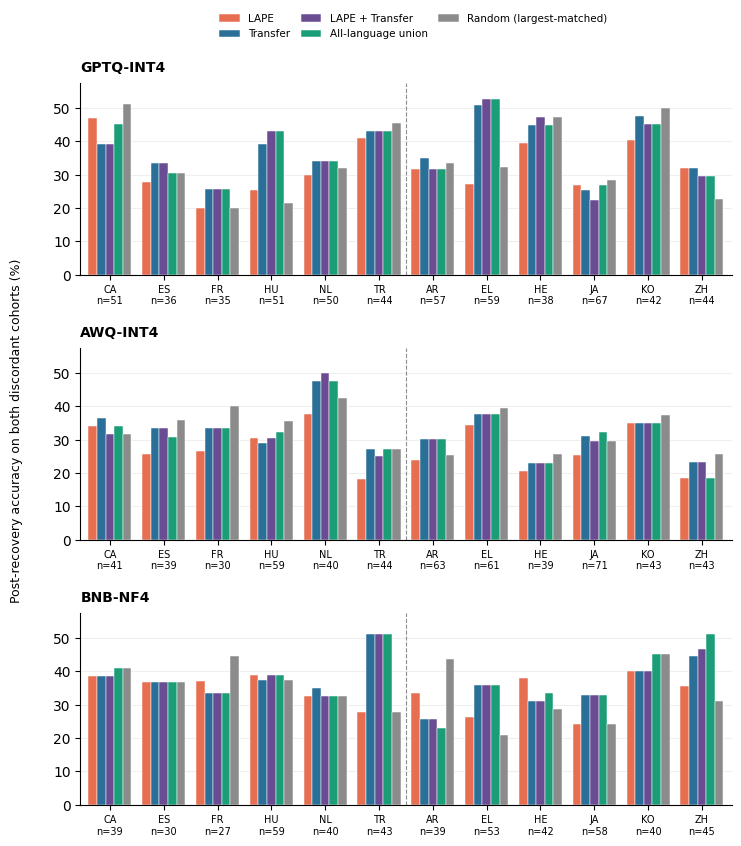

In [12]:
sample_rows = []
for method in QUANT_METHODS:
    for language in TARGET_LANGUAGES:
        for cohort in COHORTS:
            key = (method, language, cohort)
            expected = {
                row['sample_id']
                for row in SELECTED_ROWS[method][language][cohort]
            }
            if not expected:
                continue
            path = RECOVERY_PATHS[key]
            if not path.is_file():
                raise RuntimeError(f'Missing recovery output: {path}')
            frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
            if (
                len(frame) != len(expected)
                or set(frame.sample_id) != expected
                or frame.sample_id.duplicated().any()
                or not frame.selection_signature.eq(SIGNATURES[key]).all()
            ):
                raise RuntimeError(f'Incomplete or incompatible recovery output: {path}')
            for row in frame.to_dict('records'):
                for condition in RECOVERY_CONDITION_NAMES:
                    sample_rows.append({
                        'method': method,
                        'language': language,
                        'cohort': cohort,  # audit only; cohorts are pooled below
                        'sample_id': row['sample_id'],
                        'condition': condition,
                        'patched_correct': saved_bool(row[f'{condition}_correct']),
                    })

SAMPLE_DF = pd.DataFrame(sample_rows)
if SAMPLE_DF.empty:
    raise RuntimeError('No selected discordant samples were found')
if SAMPLE_DF.duplicated(['method', 'language', 'sample_id', 'condition']).any():
    raise RuntimeError('A selected case was counted more than once')
SAMPLE_DF.to_csv(OUTPUT_DIR / 'sample_level_patched_correctness.csv', index=False)

# Pool the two discordance cohorts by sample count; no separate recovery/retention rates.
SUMMARY_DF = (
    SAMPLE_DF.groupby(['method', 'language', 'condition'], as_index=False)
    .agg(n_samples=('sample_id', 'nunique'),
         patched_correct_n=('patched_correct', 'sum'))
)
SUMMARY_DF['patched_accuracy'] = (
    SUMMARY_DF.patched_correct_n / SUMMARY_DF.n_samples
)
pooled = (
    SAMPLE_DF.groupby(['method', 'condition'], as_index=False)
    .agg(n_samples=('sample_id', 'size'),
         patched_correct_n=('patched_correct', 'sum'))
)
pooled['language'] = 'ALL_LANGUAGES'
pooled['patched_accuracy'] = pooled.patched_correct_n / pooled.n_samples
SUMMARY_DF = pd.concat([SUMMARY_DF, pooled[SUMMARY_DF.columns]], ignore_index=True)
SUMMARY_DF.to_csv(OUTPUT_DIR / 'pooled_discordant_post_recovery_accuracy.csv', index=False)
display(SUMMARY_DF[SUMMARY_DF.language.ne('ALL_LANGUAGES')])
print('Pooled by sample count across both cohorts and all languages:')
display(SUMMARY_DF[SUMMARY_DF.language.eq('ALL_LANGUAGES')])

COLORS = ['#E76F51', '#2A6F97', '#6A4C93', '#1B9E77', '#8B8B8B']
LABELS = {
    'lape': 'LAPE',
    'transfer': 'Transfer',
    'lape_plus_transfer': 'LAPE + Transfer',
    'all_language_lape_plus_transfer': 'All-language union',
    'random_largest_matched': 'Random (largest-matched)',
}

# One column: one row per quantization method, one combined accuracy metric.
fig, axes = plt.subplots(len(QUANT_METHODS), 1,
                         figsize=(7.4, 8.7), squeeze=False)
axes = axes[:, 0]
x = np.arange(len(TARGET_LANGUAGES))
n_conditions = len(RECOVERY_CONDITION_NAMES)
width = min(0.16, 0.84 / n_conditions)
observed_max = 100 * SUMMARY_DF.loc[
    SUMMARY_DF.language.ne('ALL_LANGUAGES'), 'patched_accuracy'
].max()
y_upper = min(100, max(10, observed_max + 5))

for ax, method in zip(axes, QUANT_METHODS):
    subset = SUMMARY_DF[
        SUMMARY_DF.method.eq(method) &
        SUMMARY_DF.language.ne('ALL_LANGUAGES')
    ]
    counts = subset.groupby('language').n_samples.first().to_dict()
    for index, condition in enumerate(RECOVERY_CONDITION_NAMES):
        condition_rows = subset[subset.condition.eq(condition)].set_index('language')
        values = 100 * condition_rows.patched_accuracy.reindex(
            TARGET_LANGUAGES
        ).to_numpy(float)
        offset = (index - (n_conditions - 1) / 2) * width
        ax.bar(x + offset, values, width=width,
               color=COLORS[index], label=LABELS[condition],
               edgecolor='white', linewidth=0.35)
    ax.axvline(5.5, color='0.55', linestyle='--', linewidth=0.8)
    ax.set_xlim(-0.55, len(TARGET_LANGUAGES) - 0.45)
    ax.set_ylim(0, y_upper)
    ax.set_xticks(x, [f'{language.upper()}\nn={counts.get(language, 0)}'
                      for language in TARGET_LANGUAGES], fontsize=7)
    ax.set_title(method, loc='left', fontsize=10, fontweight='bold', pad=8)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.56, 0.99),
           ncol=3, frameon=False, fontsize=7.5, columnspacing=1.0)
fig.supylabel('Post-recovery accuracy on both discordant cohorts (%)',
             x=0.015, fontsize=9)
fig.subplots_adjust(left=0.11, right=0.99, top=0.90, bottom=0.07, hspace=0.38)
stem = OUTPUT_DIR / 'three_methods_pooled_discordant_post_recovery_accuracy'
fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
plt.show()


## 8. Baseline anatomy: FP16 neuron counts and cross-language overlap

This analysis characterizes the **FP16 discovery sets** used by the intervention.
It reports (i) how many language-specific (LAPE) and transfer neurons are selected
for each language, (ii) their within-language intersection, and (iii) pairwise
overlap across languages. Neurons are identified by their `(layer, channel)`
coordinates, so channels in different layers are treated as distinct. Jaccard
similarity is used for normalized overlap because the pooled transfer-score
threshold permits language-specific set sizes to differ.

These counts and overlaps are a baseline description, not evidence that
quantization changed neuron identity: the same FP16-derived masks are used for
all three interventions. Section 9 therefore compares FP16 and quantized models
on the same neuron coordinates and the same KLAR prompts.


,language,script_group,transfer_n,lape_n,intersection_n,union_n,jaccard,overlap_coefficient
0,ca,Latin,1045,21,0,1066,0.000000,0.000000
1,es,Latin,965,22,0,987,0.000000,0.000000
2,fr,Latin,1015,21,1,1035,0.000966,0.047619
3,hu,Latin,1165,20,0,1185,0.000000,0.000000
4,nl,Latin,1009,14,0,1023,0.000000,0.000000
5,tr,Latin,1116,18,1,1133,0.000883,0.055556
6,ar,Non-Latin,1119,37,0,1156,0.000000,0.000000
7,el,Non-Latin,1120,12,1,1131,0.000884,0.083333
8,he,Non-Latin,1271,14,0,1285,0.000000,0.000000
9,ja,Non-Latin,1557,63,5,1615,0.003096,0.079365


,script_group,languages,transfer_mean,transfer_std,lape_mean,lape_std,intersection_mean,jaccard_mean,jaccard_std
0,Latin,6,1052.500000,74.430504,19.333333,2.943920,0.333333,0.000308,0.000478
1,Non-Latin,6,1241.333333,165.465001,43.000000,26.298289,1.500000,0.001066,0.001170


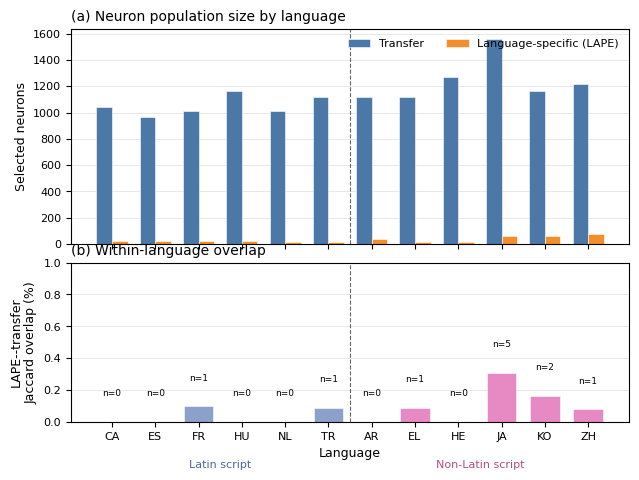

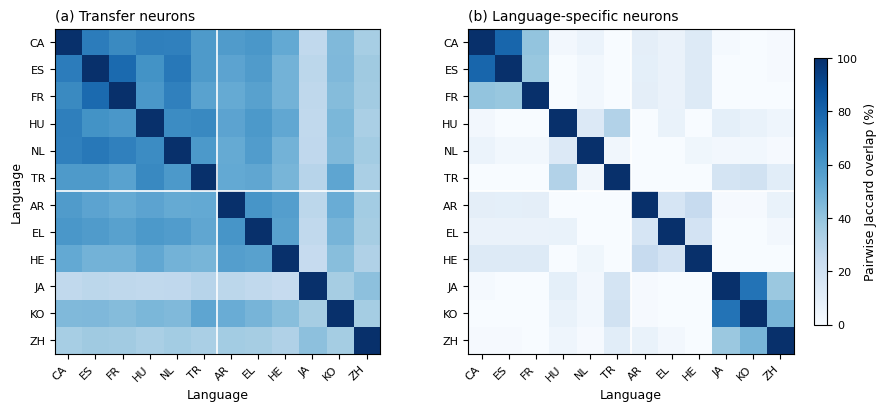

In [13]:
# Appendix figures: neuron counts and overlap across languages
NEURON_ANALYSIS_DIR = OUTPUT_DIR / 'functional_neuron_overlap_and_counts'
NEURON_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)


def layer_channel_set(by_layer):
    """Represent a neuron by its (decoder layer, MLP channel) coordinate."""
    return {
        (int(layer), int(neuron))
        for layer in RECOVERY_LAYERS
        for neuron in by_layer[layer].tolist()
    }


transfer_sets = {
    language: layer_channel_set(PAPER_MASKS[language])
    for language in TARGET_LANGUAGES
}
lape_sets = {
    language: layer_channel_set({
        layer: layer_indices(recovery_lape_df, language, layer)
        for layer in RECOVERY_LAYERS
    })
    for language in TARGET_LANGUAGES
}


def jaccard(left, right):
    union = left | right
    return len(left & right) / len(union) if union else np.nan


# Per-language counts and within-language overlap between the two populations.
count_rows = []
layer_rows = []
for language in TARGET_LANGUAGES:
    transfer = transfer_sets[language]
    lape = lape_sets[language]
    intersection = transfer & lape
    union = transfer | lape
    count_rows.append({
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
        'transfer_n': len(transfer),
        'lape_n': len(lape),
        'intersection_n': len(intersection),
        'union_n': len(union),
        'jaccard': len(intersection) / len(union) if union else np.nan,
        'overlap_coefficient': (
            len(intersection) / min(len(transfer), len(lape))
            if transfer and lape else np.nan
        ),
    })
    for layer in RECOVERY_LAYERS:
        transfer_layer = {
            neuron for selected_layer, neuron in transfer
            if selected_layer == layer
        }
        lape_layer = {
            neuron for selected_layer, neuron in lape
            if selected_layer == layer
        }
        layer_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'layer': layer,
            'transfer_n': len(transfer_layer),
            'lape_n': len(lape_layer),
            'intersection_n': len(transfer_layer & lape_layer),
            'jaccard': jaccard(transfer_layer, lape_layer),
        })

COUNT_DF = pd.DataFrame(count_rows)
LAYER_COUNT_DF = pd.DataFrame(layer_rows)
COUNT_DF.to_csv(
    NEURON_ANALYSIS_DIR / 'neuron_counts_and_within_language_overlap.csv',
    index=False,
)
LAYER_COUNT_DF.to_csv(
    NEURON_ANALYSIS_DIR / 'neuron_counts_and_overlap_by_layer.csv',
    index=False,
)

group_summary = (
    COUNT_DF.groupby('script_group', as_index=False)
    .agg(
        languages=('language', 'nunique'),
        transfer_mean=('transfer_n', 'mean'),
        transfer_std=('transfer_n', 'std'),
        lape_mean=('lape_n', 'mean'),
        lape_std=('lape_n', 'std'),
        intersection_mean=('intersection_n', 'mean'),
        jaccard_mean=('jaccard', 'mean'),
        jaccard_std=('jaccard', 'std'),
    )
)
group_summary.to_csv(
    NEURON_ANALYSIS_DIR / 'neuron_counts_and_overlap_by_script.csv',
    index=False,
)
display(COUNT_DF)
display(group_summary)


# Figure A: population sizes and within-language LAPE--transfer overlap.
plt.rcParams.update({
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
})

x = np.arange(len(TARGET_LANGUAGES))
width = 0.36
fig, axes = plt.subplots(
    2, 1, figsize=(7.2, 5.1), sharex=True,
    gridspec_kw={'height_ratios': [1.35, 1.0], 'hspace': 0.10},
)

axes[0].bar(
    x - width / 2, COUNT_DF['transfer_n'], width,
    color='#4C78A8', label='Transfer', edgecolor='white', linewidth=0.4,
)
axes[0].bar(
    x + width / 2, COUNT_DF['lape_n'], width,
    color='#F28E2B', label='Language-specific (LAPE)',
    edgecolor='white', linewidth=0.4,
)
axes[0].set_ylabel('Selected neurons')
axes[0].set_title('(a) Neuron population size by language', loc='left')
axes[0].legend(frameon=False, ncol=2, loc='upper right')
axes[0].grid(axis='y', color='#D9D9D9', linewidth=0.6, alpha=0.7)
axes[0].set_axisbelow(True)

overlap_pct = 100 * COUNT_DF['jaccard'].to_numpy(float)
bar_colors = [
    '#8DA0CB' if group == 'Latin' else '#E78AC3'
    for group in COUNT_DF['script_group']
]
axes[1].bar(
    x, overlap_pct, width=0.68, color=bar_colors,
    edgecolor='white', linewidth=0.4,
)
for position, percentage, overlap_n in zip(
    x, overlap_pct, COUNT_DF['intersection_n']
):
    axes[1].text(
        position, percentage + max(0.15, np.nanmax(overlap_pct) * 0.015),
        f'n={int(overlap_n)}', ha='center', va='bottom', fontsize=6.5,
    )
axes[1].set_ylabel('LAPE--transfer\nJaccard overlap (%)')
axes[1].set_title('(b) Within-language overlap', loc='left')
axes[1].grid(axis='y', color='#D9D9D9', linewidth=0.6, alpha=0.7)
axes[1].set_axisbelow(True)
axes[1].set_ylim(0, max(1.0, np.nanmax(overlap_pct) * 1.20))
axes[1].set_xticks(x, [language.upper() for language in TARGET_LANGUAGES])
axes[1].set_xlabel('Language')

# The configured ordering places six Latin languages before six non-Latin ones.
for axis in axes:
    axis.axvline(5.5, color='#666666', linestyle='--', linewidth=0.8)
axes[1].text(
    2.5, -0.24, 'Latin script', transform=axes[1].get_xaxis_transform(),
    ha='center', va='top', color='#4C669F', fontsize=8,
)
axes[1].text(
    8.5, -0.24, 'Non-Latin script', transform=axes[1].get_xaxis_transform(),
    ha='center', va='top', color='#B34D87', fontsize=8,
)

fig.savefig(
    NEURON_ANALYSIS_DIR / 'neuron_counts_and_within_language_overlap.pdf',
    bbox_inches='tight',
)
fig.savefig(
    NEURON_ANALYSIS_DIR / 'neuron_counts_and_within_language_overlap.png',
    dpi=300, bbox_inches='tight',
)
plt.show()


# Pairwise Jaccard matrices quantify how much each population is shared
# between languages. Diagonal entries are one by definition.
def pairwise_jaccard_frame(language_sets):
    matrix = np.zeros((len(TARGET_LANGUAGES), len(TARGET_LANGUAGES)))
    for row_index, left_language in enumerate(TARGET_LANGUAGES):
        for column_index, right_language in enumerate(TARGET_LANGUAGES):
            matrix[row_index, column_index] = jaccard(
                language_sets[left_language], language_sets[right_language]
            )
    return pd.DataFrame(
        matrix, index=TARGET_LANGUAGES, columns=TARGET_LANGUAGES
    )


TRANSFER_JACCARD_DF = pairwise_jaccard_frame(transfer_sets)
LAPE_JACCARD_DF = pairwise_jaccard_frame(lape_sets)
TRANSFER_JACCARD_DF.to_csv(
    NEURON_ANALYSIS_DIR / 'pairwise_transfer_jaccard.csv'
)
LAPE_JACCARD_DF.to_csv(
    NEURON_ANALYSIS_DIR / 'pairwise_lape_jaccard.csv'
)

fig, axes = plt.subplots(1, 2, figsize=(9.1, 4.0), constrained_layout=True)
for axis, matrix, title in [
    (axes[0], TRANSFER_JACCARD_DF, '(a) Transfer neurons'),
    (axes[1], LAPE_JACCARD_DF, '(b) Language-specific neurons'),
]:
    image = axis.imshow(
        100 * matrix.to_numpy(float), cmap='Blues', vmin=0, vmax=100,
        aspect='equal', interpolation='nearest',
    )
    axis.set_title(title, loc='left')
    axis.set_xticks(
        range(len(TARGET_LANGUAGES)),
        [language.upper() for language in TARGET_LANGUAGES],
        rotation=45, ha='right',
    )
    axis.set_yticks(
        range(len(TARGET_LANGUAGES)),
        [language.upper() for language in TARGET_LANGUAGES],
    )
    axis.axhline(5.5, color='white', linewidth=1.2)
    axis.axvline(5.5, color='white', linewidth=1.2)
    axis.set_xlabel('Language')
axes[0].set_ylabel('Language')

colorbar = fig.colorbar(image, ax=axes, shrink=0.82, pad=0.025)
colorbar.set_label('Pairwise Jaccard overlap (%)')
fig.savefig(
    NEURON_ANALYSIS_DIR / 'pairwise_cross_language_neuron_overlap.pdf',
    bbox_inches='tight',
)
fig.savefig(
    NEURON_ANALYSIS_DIR / 'pairwise_cross_language_neuron_overlap.png',
    dpi=300, bbox_inches='tight',
)
plt.show()


## 9. Quantization-induced changes in functional-neuron properties

This section measures four properties requested for the functional-neuron
analysis: **distribution, overlap, selectivity, and MLP contribution**. To keep
the comparison causal and paired, it does not rediscover or rename LAPE and
transfer neurons in each quantized model. Instead, it evaluates FP16 and all
three quantizers on exactly the same union of FP16-derived LAPE/transfer
coordinates, the same 500 aligned KLAR facts per language, the same prompt
template, and the last non-padding prompt token.

For neuron $j$ in layer $l$, the MLP output contribution is

\[
c_{l,j}(x)=z_{l,j}(x)W^{\mathrm{down}}_{l,:,j},
\qquad
\lVert c_{l,j}(x)\rVert_2
=|z_{l,j}(x)|\,\lVert W^{\mathrm{down}}_{l,:,j}\rVert_2.
\]

The notebook averages this exact per-neuron contribution norm over examples.
It then reports:

1. **Distribution:** the fraction of contribution mass assigned to each layer.
2. **Overlap:** Jaccard overlap and FP16 retention of the most-contributing
   neurons within each fixed functional population.
3. **Selectivity:** normalized entropy of each neuron's contribution profile
   across languages, together with preferred-language changes.
4. **MLP contribution:** paired relative and log-ratio changes in contribution
   magnitude at the same `(layer, channel)` coordinate.

This design supports claims about changes in the properties of the identified
functional neurons. It deliberately does **not** claim that quantization creates
new LAPE/transfer identities outside the FP16 discovery universe; that stronger
claim would require rerunning the original Tatoeba and Wikipedia discovery
pipelines separately for every quantizer.


In [14]:
# Configuration and cached profile collection for Functional Neuron Properties
PROPERTY_DIR = OUTPUT_DIR / 'functional_neuron_properties'
PROPERTY_DIR.mkdir(parents=True, exist_ok=True)

PROPERTY_MODELS = ['FP16'] + QUANT_METHODS
PROPERTY_POPULATIONS = ['lape', 'transfer', 'lape_plus_transfer']
PROPERTY_BATCH_SIZE = 16
PROPERTY_ACTIVE_TOP_RATE = 0.10
PROPERTY_EPS = 1e-12

# The all-language LAPE+transfer union is the shared coordinate universe.
PROPERTY_UNIVERSE = {
    layer: ALL_LANGUAGE_LAPE_TRANSFER_UNION[layer].cpu().long()
    for layer in RECOVERY_LAYERS
}


def property_cache_path(model_name):
    stem = model_name.lower().replace('-', '_')
    return PROPERTY_DIR / f'{stem}_functional_neuron_profiles.csv'


def property_signature(model_name):
    checkpoint = (
        FP16_CHECKPOINT if model_name == 'FP16'
        else Path(QUANT_SPECS[model_name]['checkpoint'])
    )
    payload = {
        'protocol': 'klar500_fixed_fp16_functional_neuron_properties_v1',
        'model': model_name,
        'checkpoint': str(checkpoint),
        'record_ids_hash': SELECTED_RECORD_IDS_HASH,
        'languages': TARGET_LANGUAGES,
        'layers': RECOVERY_LAYERS,
        'universe': {
            str(layer): PROPERTY_UNIVERSE[layer].tolist()
            for layer in RECOVERY_LAYERS
        },
        'prompt': {
            'n_shot': KLAR_N_SHOT,
            'max_length': KLAR_MAX_LENGTH,
            'token': 'last_nonpadding_prompt_token',
        },
    }
    return hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode('utf-8')
    ).hexdigest()


@torch.no_grad()
def property_weight_norms(model_name, model):
    """Return ||W_down[:, j]|| for every shared functional coordinate."""
    layers = decoder_layers(model)
    result = {}
    for layer in RECOVERY_LAYERS:
        module = layers[layer].mlp.down_proj
        if model_name == 'GPTQ-INT4':
            dense = serialized_gptq_down_weight(layer, module)
        else:
            dense = dense_linear_weight(module)
        indices = PROPERTY_UNIVERSE[layer].to(dense.device)
        result[layer] = (
            dense.float().index_select(1, indices).norm(dim=0).cpu()
        )
        del dense
    return result


@torch.no_grad()
def collect_language_activation_profile(model, rows):
    """Average signed and absolute down_proj inputs at the last prompt token."""
    layers = decoder_layers(model)
    device = input_device(model)
    sums = {
        layer: torch.zeros(len(PROPERTY_UNIVERSE[layer]), dtype=torch.float64)
        for layer in RECOVERY_LAYERS
    }
    abs_sums = {
        layer: torch.zeros(len(PROPERTY_UNIVERSE[layer]), dtype=torch.float64)
        for layer in RECOVERY_LAYERS
    }
    captured = {}
    handles = []

    class _StopAfterPropertyLayers(RuntimeError):
        pass

    for layer in RECOVERY_LAYERS:
        module = layers[layer].mlp.down_proj
        module_device = down_output_device(module, fallback=device)
        indices = PROPERTY_UNIVERSE[layer].to(module_device)

        def capture(_module, inputs, layer=layer, indices=indices):
            # Prompts are left padded, so the final sequence position is valid.
            captured[layer] = (
                inputs[0][:, -1, :]
                .index_select(-1, indices)
                .detach()
                .float()
                .cpu()
            )

        handles.append(module.register_forward_pre_hook(capture))

    # Only layers 0--7 are analyzed. Stop after the final requested decoder
    # layer so every batch does not unnecessarily traverse the remaining
    # layers. The target layer has completed, so all requested hooks have fired.
    def stop_after_last_layer(_module, _inputs, _output):
        raise _StopAfterPropertyLayers()

    handles.append(
        layers[max(RECOVERY_LAYERS)].register_forward_hook(
            stop_after_last_layer
        )
    )

    count = 0
    try:
        for start in tqdm(
            range(0, len(rows), PROPERTY_BATCH_SIZE),
            desc='Collecting functional-neuron profiles',
            leave=False,
        ):
            batch_rows = rows[start:start + PROPERTY_BATCH_SIZE]
            batch = encode_klar_prompt_batch(batch_rows)
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            if not bool(attention_mask[:, -1].all()):
                raise RuntimeError('The final prompt position must be non-padding.')
            position_ids = attention_mask.long().cumsum(-1) - 1
            position_ids.masked_fill_(attention_mask == 0, 0)
            captured.clear()
            try:
                model.model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    position_ids=position_ids,
                    use_cache=False,
                    return_dict=True,
                )
            except _StopAfterPropertyLayers:
                pass
            else:
                raise RuntimeError(
                    'The layer-7 early-stop hook did not execute.'
                )
            if set(captured) != set(RECOVERY_LAYERS):
                missing = set(RECOVERY_LAYERS) - set(captured)
                raise RuntimeError(f'Missing MLP activations for layers: {missing}')
            for layer in RECOVERY_LAYERS:
                values = captured[layer].double()
                sums[layer] += values.sum(dim=0)
                abs_sums[layer] += values.abs().sum(dim=0)
            count += len(batch_rows)
    finally:
        for handle in handles:
            handle.remove()

    if count != len(rows):
        raise RuntimeError(f'Profile count mismatch: {count} != {len(rows)}')
    return {
        layer: {
            'mean_activation': (sums[layer] / count).float(),
            'mean_abs_activation': (abs_sums[layer] / count).float(),
        }
        for layer in RECOVERY_LAYERS
    }


def validate_property_cache(frame, model_name, signature):
    required = {
        'model', 'language', 'layer', 'neuron_index',
        'mean_activation', 'mean_abs_activation', 'down_weight_norm',
        'mean_contribution_norm', 'profile_signature',
    }
    if not required.issubset(frame.columns):
        return False
    if not frame['model'].eq(model_name).all():
        return False
    if not frame['profile_signature'].eq(signature).all():
        return False
    expected = sum(len(PROPERTY_UNIVERSE[layer]) for layer in RECOVERY_LAYERS)
    if len(frame) != expected * len(TARGET_LANGUAGES):
        return False
    return not frame.duplicated(['language', 'layer', 'neuron_index']).any()


def require_property_prefix_cuda(model, name):
    """Require only the model prefix used by this analysis to be on CUDA.

    Later decoder layers, the final norm, and lm_head may be CPU/disk offloaded:
    the profiling forward pass raises its early-stop signal after layer 7, so
    those modules are never executed.
    """
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA unavailable; this analysis requires a GPU.')
    embedding_device = input_device(model)
    if embedding_device.type != 'cuda':
        raise RuntimeError(
            f'{name}: input embeddings are on {embedding_device}, not CUDA.'
        )

    layers = decoder_layers(model)
    bad_layers = {}
    for layer in RECOVERY_LAYERS:
        devices = {
            tensor.device.type
            for tensor in list(layers[layer].parameters(recurse=True))
            + list(layers[layer].buffers(recurse=True))
            if tensor.numel() > 0
        }
        if devices and devices != {'cuda'}:
            bad_layers[layer] = sorted(devices)
    if bad_layers:
        raise RuntimeError(
            f'{name}: analyzed decoder layers are not fully on CUDA: '
            f'{bad_layers}'
        )

    placement = getattr(model, 'hf_device_map', None)
    ignored_offload = {}
    if placement is not None:
        ignored_offload = {
            key: value
            for key, value in placement.items()
            if str(value) in ('cpu', 'disk', 'meta')
        }
    print(
        name,
        'property-analysis prefix is on CUDA;',
        'unused offloaded modules:',
        ignored_offload or 'none',
    )


profile_frames = []
for model_name in PROPERTY_MODELS:
    cache_path = property_cache_path(model_name)
    signature = property_signature(model_name)
    cached = None
    if cache_path.is_file():
        candidate = pd.read_csv(cache_path)
        if validate_property_cache(candidate, model_name, signature):
            cached = candidate
            print(model_name, ': using cached functional-neuron profiles')
    if cached is not None:
        profile_frames.append(cached)
        continue

    print(model_name, ': collecting functional-neuron profiles')
    model = load_model(model_name)
    require_property_prefix_cuda(model, model_name)
    try:
        weight_norms = property_weight_norms(model_name, model)
        rows_out = []
        for language in TARGET_LANGUAGES:
            profile = collect_language_activation_profile(
                model, KLAR_ROWS[language]
            )
            for layer in RECOVERY_LAYERS:
                indices = PROPERTY_UNIVERSE[layer]
                mean_activation = profile[layer]['mean_activation']
                mean_abs_activation = profile[layer]['mean_abs_activation']
                weight_norm = weight_norms[layer]
                contribution = mean_abs_activation * weight_norm
                for position, neuron_index in enumerate(indices.tolist()):
                    rows_out.append({
                        'model': model_name,
                        'language': language,
                        'layer': int(layer),
                        'neuron_index': int(neuron_index),
                        'mean_activation': float(mean_activation[position]),
                        'mean_abs_activation': float(mean_abs_activation[position]),
                        'down_weight_norm': float(weight_norm[position]),
                        'mean_contribution_norm': float(contribution[position]),
                        'profile_signature': signature,
                    })
        cached = pd.DataFrame(rows_out)
        if not validate_property_cache(cached, model_name, signature):
            raise RuntimeError(f'Generated invalid property cache for {model_name}')
        cached.to_csv(cache_path, index=False)
        profile_frames.append(cached)
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

PROFILE_DF = pd.concat(profile_frames, ignore_index=True)
print('Functional-neuron profile rows:', len(PROFILE_DF))
display(PROFILE_DF.head())


FP16 : using cached functional-neuron profiles
GPTQ-INT4 : using cached functional-neuron profiles
AWQ-INT4 : using cached functional-neuron profiles
BNB-NF4 : using cached functional-neuron profiles
Functional-neuron profile rows: 159360


,model,language,layer,neuron_index,mean_activation,mean_abs_activation,down_weight_norm,mean_contribution_norm,profile_signature
0,FP16,ca,0,5,-0.000348,0.000368,0.754088,0.000278,50b24f096f7edda11af885655a74ae2c26cec45c7ac5d7...
1,FP16,ca,0,19,0.003088,0.003088,0.726212,0.002243,50b24f096f7edda11af885655a74ae2c26cec45c7ac5d7...
2,FP16,ca,0,20,0.007155,0.007155,0.724121,0.005181,50b24f096f7edda11af885655a74ae2c26cec45c7ac5d7...
3,FP16,ca,0,31,-0.002596,0.002596,0.848338,0.002202,50b24f096f7edda11af885655a74ae2c26cec45c7ac5d7...
4,FP16,ca,0,42,0.003018,0.003018,0.771424,0.002328,50b24f096f7edda11af885655a74ae2c26cec45c7ac5d7...


In [15]:
# Summaries for distribution, overlap, selectivity, and MLP contribution
def coordinate_set(frame):
    return set(zip(
        frame['layer'].astype(int),
        frame['neuron_index'].astype(int),
    ))


def population_coordinates(language, population):
    by_layer = SHARED_MASKS[language][population]
    return {
        (int(layer), int(neuron))
        for layer in RECOVERY_LAYERS
        for neuron in by_layer[layer].tolist()
    }


def add_population_membership(frame):
    pieces = []
    for language in TARGET_LANGUAGES:
        language_frame = frame[frame.language.eq(language)]
        for population in PROPERTY_POPULATIONS:
            coordinates = population_coordinates(language, population)
            keys = list(zip(
                language_frame.layer.astype(int),
                language_frame.neuron_index.astype(int),
            ))
            selected = np.fromiter(
                (key in coordinates for key in keys),
                dtype=bool,
                count=len(keys),
            )
            subset = language_frame.loc[selected].copy()
            subset['population'] = population
            pieces.append(subset)
    return pd.concat(pieces, ignore_index=True)


POPULATION_PROFILE_DF = add_population_membership(PROFILE_DF)
POPULATION_PROFILE_DF.to_csv(
    PROPERTY_DIR / 'functional_neuron_profiles_by_population.csv',
    index=False,
)


# 1. Distribution: contribution mass across layers for each fixed population.
distribution = (
    POPULATION_PROFILE_DF
    .groupby(['model', 'language', 'population', 'layer'], as_index=False)
    .agg(
        neuron_n=('neuron_index', 'nunique'),
        contribution_mass=('mean_contribution_norm', 'sum'),
        contribution_mean=('mean_contribution_norm', 'mean'),
    )
)
distribution['layer_mass_share'] = (
    distribution['contribution_mass']
    / distribution.groupby(
        ['model', 'language', 'population']
    )['contribution_mass'].transform('sum').clip(lower=PROPERTY_EPS)
)
distribution.to_csv(
    PROPERTY_DIR / 'layerwise_contribution_distribution.csv', index=False
)


def js_divergence(left, right, eps=PROPERTY_EPS):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left = left / max(left.sum(), eps)
    right = right / max(right.sum(), eps)
    middle = 0.5 * (left + right)
    left_term = np.where(left > 0, left * np.log2(left / np.maximum(middle, eps)), 0)
    right_term = np.where(right > 0, right * np.log2(right / np.maximum(middle, eps)), 0)
    return float(0.5 * (left_term.sum() + right_term.sum()))


distribution_change_rows = []
for model_name in QUANT_METHODS:
    for language in TARGET_LANGUAGES:
        for population in PROPERTY_POPULATIONS:
            fp = (
                distribution[
                    distribution.model.eq('FP16')
                    & distribution.language.eq(language)
                    & distribution.population.eq(population)
                ]
                .set_index('layer')['layer_mass_share']
                .reindex(RECOVERY_LAYERS, fill_value=0.0)
            )
            quant = (
                distribution[
                    distribution.model.eq(model_name)
                    & distribution.language.eq(language)
                    & distribution.population.eq(population)
                ]
                .set_index('layer')['layer_mass_share']
                .reindex(RECOVERY_LAYERS, fill_value=0.0)
            )
            distribution_change_rows.append({
                'model': model_name,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'population': population,
                'layer_distribution_jsd': js_divergence(fp, quant),
            })

DISTRIBUTION_CHANGE_DF = pd.DataFrame(distribution_change_rows)
DISTRIBUTION_CHANGE_DF.to_csv(
    PROPERTY_DIR / 'distribution_change_from_fp16.csv', index=False
)


# 2. Overlap: top-contributing coordinates within each fixed population.
active_sets = {}
active_rows = []
for (model_name, language, population), frame in POPULATION_PROFILE_DF.groupby(
    ['model', 'language', 'population'], sort=False
):
    count = max(1, math.ceil(len(frame) * PROPERTY_ACTIVE_TOP_RATE))
    active = frame.nlargest(count, 'mean_contribution_norm')
    active_sets[model_name, language, population] = coordinate_set(active)
    for layer, neuron in sorted(active_sets[model_name, language, population]):
        active_rows.append({
            'model': model_name,
            'language': language,
            'population': population,
            'layer': layer,
            'neuron_index': neuron,
        })

ACTIVE_DF = pd.DataFrame(active_rows)
ACTIVE_DF.to_csv(
    PROPERTY_DIR / 'top_contributing_functional_neurons.csv', index=False
)

overlap_rows = []
for model_name in QUANT_METHODS:
    for language in TARGET_LANGUAGES:
        for population in PROPERTY_POPULATIONS:
            fp_set = active_sets['FP16', language, population]
            quant_set = active_sets[model_name, language, population]
            intersection = fp_set & quant_set
            union = fp_set | quant_set
            overlap_rows.append({
                'model': model_name,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'population': population,
                'fp16_active_n': len(fp_set),
                'quant_active_n': len(quant_set),
                'intersection_n': len(intersection),
                'jaccard': len(intersection) / len(union) if union else np.nan,
                'fp16_retention': (
                    len(intersection) / len(fp_set) if fp_set else np.nan
                ),
            })

OVERLAP_CHANGE_DF = pd.DataFrame(overlap_rows)
OVERLAP_CHANGE_DF.to_csv(
    PROPERTY_DIR / 'active_neuron_overlap_with_fp16.csv', index=False
)


# 3. Selectivity: entropy of contribution profiles across the 12 languages.
selectivity_rows = []
normalizer = math.log(len(TARGET_LANGUAGES))
for (model_name, layer, neuron), frame in PROFILE_DF.groupby(
    ['model', 'layer', 'neuron_index'], sort=False
):
    values = (
        frame.set_index('language')['mean_contribution_norm']
        .reindex(TARGET_LANGUAGES)
        .to_numpy(float)
    )
    if not np.isfinite(values).all():
        raise RuntimeError(
            f'Non-finite selectivity profile: {model_name}/L{layer}/N{neuron}'
        )
    total = values.sum()
    if total <= PROPERTY_EPS:
        selectivity = 0.0
        preferred_language = ''
    else:
        probabilities = values / total
        entropy = -np.sum(
            np.where(
                probabilities > 0,
                probabilities * np.log(np.maximum(probabilities, PROPERTY_EPS)),
                0.0,
            )
        )
        selectivity = 1.0 - entropy / normalizer
        preferred_language = TARGET_LANGUAGES[int(values.argmax())]
    selectivity_rows.append({
        'model': model_name,
        'layer': int(layer),
        'neuron_index': int(neuron),
        'selectivity': float(selectivity),
        'preferred_language': preferred_language,
    })

SELECTIVITY_DF = pd.DataFrame(selectivity_rows)
SELECTIVITY_DF.to_csv(
    PROPERTY_DIR / 'neuron_language_selectivity.csv', index=False
)

fp_selectivity = SELECTIVITY_DF[SELECTIVITY_DF.model.eq('FP16')].rename(
    columns={
        'selectivity': 'fp16_selectivity',
        'preferred_language': 'fp16_preferred_language',
    }
)[['layer', 'neuron_index', 'fp16_selectivity', 'fp16_preferred_language']]
selectivity_changes = []
for model_name in QUANT_METHODS:
    quant = SELECTIVITY_DF[SELECTIVITY_DF.model.eq(model_name)].rename(
        columns={
            'selectivity': 'quant_selectivity',
            'preferred_language': 'quant_preferred_language',
        }
    )
    joined = quant.merge(fp_selectivity, on=['layer', 'neuron_index'])
    joined['model'] = model_name
    joined['selectivity_delta'] = (
        joined['quant_selectivity'] - joined['fp16_selectivity']
    )
    joined['preferred_language_changed'] = (
        joined['quant_preferred_language']
        != joined['fp16_preferred_language']
    )
    selectivity_changes.append(joined)

SELECTIVITY_CHANGE_DF = pd.concat(selectivity_changes, ignore_index=True)
SELECTIVITY_CHANGE_DF['fp16_preferred_script_group'] = (
    SELECTIVITY_CHANGE_DF['fp16_preferred_language'].map(
        LANGUAGE_SCRIPT_GROUPS
    )
)
SELECTIVITY_CHANGE_DF.to_csv(
    PROPERTY_DIR / 'selectivity_change_from_fp16.csv', index=False
)

# First average neuron-level selectivity changes within each FP16-preferred
# language. This gives every language one observation in the Latin/non-Latin
# comparison rather than weighting languages by their number of neurons.
SELECTIVITY_LANGUAGE_DF = (
    SELECTIVITY_CHANGE_DF.dropna(
        subset=['fp16_preferred_script_group']
    )
    .groupby(
        [
            'model', 'fp16_preferred_language',
            'fp16_preferred_script_group',
        ],
        as_index=False,
    )
    .agg(
        mean_selectivity_delta=('selectivity_delta', 'mean'),
        preferred_language_change_rate=(
            'preferred_language_changed', 'mean'
        ),
        neuron_n=('neuron_index', 'size'),
    )
)
SELECTIVITY_LANGUAGE_DF.to_csv(
    PROPERTY_DIR / 'selectivity_change_by_preferred_language.csv',
    index=False,
)


# 4. MLP contribution: paired change at the same language/layer/neuron.
join_keys = ['language', 'layer', 'neuron_index']
fp_profiles = PROFILE_DF[PROFILE_DF.model.eq('FP16')][
    join_keys + ['mean_contribution_norm']
].rename(columns={'mean_contribution_norm': 'fp16_contribution'})

contribution_changes = []
for model_name in QUANT_METHODS:
    quant = PROFILE_DF[PROFILE_DF.model.eq(model_name)][
        join_keys + ['mean_contribution_norm']
    ].rename(columns={'mean_contribution_norm': 'quant_contribution'})
    joined = quant.merge(fp_profiles, on=join_keys, validate='one_to_one')
    joined['model'] = model_name
    joined['script_group'] = joined['language'].map(LANGUAGE_SCRIPT_GROUPS)
    denominator = joined['fp16_contribution'].clip(lower=PROPERTY_EPS)
    joined['relative_contribution_change'] = (
        (joined['quant_contribution'] - joined['fp16_contribution'])
        / denominator
    )
    joined['log2_contribution_ratio'] = np.log2(
        (joined['quant_contribution'] + PROPERTY_EPS)
        / (joined['fp16_contribution'] + PROPERTY_EPS)
    )
    contribution_changes.append(joined)

CONTRIBUTION_CHANGE_DF = pd.concat(contribution_changes, ignore_index=True)
CONTRIBUTION_CHANGE_DF.to_csv(
    PROPERTY_DIR / 'mlp_contribution_change_from_fp16.csv', index=False
)


# Compact language-level summaries used by the appendix table and plots.
CONTRIBUTION_SUMMARY_DF = (
    CONTRIBUTION_CHANGE_DF
    .groupby(['model', 'language', 'script_group'], as_index=False)
    .agg(
        median_relative_contribution_change=(
            'relative_contribution_change', 'median'
        ),
        median_log2_contribution_ratio=('log2_contribution_ratio', 'median'),
        mean_abs_log2_contribution_ratio=(
            'log2_contribution_ratio', lambda values: np.mean(np.abs(values))
        ),
    )
)
CONTRIBUTION_SUMMARY_DF.to_csv(
    PROPERTY_DIR / 'mlp_contribution_change_summary.csv', index=False
)

SELECTIVITY_SUMMARY_DF = (
    SELECTIVITY_CHANGE_DF.groupby('model', as_index=False)
    .agg(
        mean_selectivity_delta=('selectivity_delta', 'mean'),
        median_selectivity_delta=('selectivity_delta', 'median'),
        preferred_language_change_rate=('preferred_language_changed', 'mean'),
    )
)
SELECTIVITY_SUMMARY_DF.to_csv(
    PROPERTY_DIR / 'selectivity_change_summary.csv', index=False
)


# A single tidy table for Latin versus non-Latin comparisons in all panels.
script_summary_frames = []
for metric_name, frame, value_column, group_column in [
    (
        'layer_distribution_jsd',
        DISTRIBUTION_CHANGE_DF[
            DISTRIBUTION_CHANGE_DF.population.eq('lape_plus_transfer')
        ],
        'layer_distribution_jsd',
        'script_group',
    ),
    (
        'active_neuron_jaccard',
        OVERLAP_CHANGE_DF[
            OVERLAP_CHANGE_DF.population.eq('lape_plus_transfer')
        ],
        'jaccard',
        'script_group',
    ),
    (
        'selectivity_delta',
        SELECTIVITY_LANGUAGE_DF,
        'mean_selectivity_delta',
        'fp16_preferred_script_group',
    ),
    (
        'relative_mlp_contribution_change',
        CONTRIBUTION_SUMMARY_DF,
        'median_relative_contribution_change',
        'script_group',
    ),
]:
    summary = (
        frame.groupby(['model', group_column])[value_column]
        .agg(mean='mean', std='std', count='count')
        .reset_index()
        .rename(columns={group_column: 'script_group'})
    )
    summary['metric'] = metric_name
    script_summary_frames.append(summary)

SCRIPT_GROUP_SUMMARY_DF = pd.concat(
    script_summary_frames, ignore_index=True
)
SCRIPT_GROUP_SUMMARY_DF.to_csv(
    PROPERTY_DIR / 'functional_properties_by_script_group.csv',
    index=False,
)

display(DISTRIBUTION_CHANGE_DF.groupby(['model', 'population']).agg(
    layer_distribution_jsd_mean=('layer_distribution_jsd', 'mean'),
    layer_distribution_jsd_std=('layer_distribution_jsd', 'std'),
))
display(OVERLAP_CHANGE_DF.groupby(['model', 'population']).agg(
    jaccard_mean=('jaccard', 'mean'),
    fp16_retention_mean=('fp16_retention', 'mean'),
))
display(SELECTIVITY_SUMMARY_DF)
display(SCRIPT_GROUP_SUMMARY_DF)
display(CONTRIBUTION_SUMMARY_DF.groupby('model').agg(
    median_relative_change=('median_relative_contribution_change', 'median'),
    mean_abs_log2_change=('mean_abs_log2_contribution_ratio', 'mean'),
))


/tmp/ipykernel_1665/2523826763.py:73: RuntimeWarning: divide by zero encountered in log2
  left_term = np.where(left > 0, left * np.log2(left / np.maximum(middle, eps)), 0)
/tmp/ipykernel_1665/2523826763.py:73: RuntimeWarning: invalid value encountered in multiply
  left_term = np.where(left > 0, left * np.log2(left / np.maximum(middle, eps)), 0)
/tmp/ipykernel_1665/2523826763.py:74: RuntimeWarning: divide by zero encountered in log2
  right_term = np.where(right > 0, right * np.log2(right / np.maximum(middle, eps)), 0)
/tmp/ipykernel_1665/2523826763.py:74: RuntimeWarning: invalid value encountered in multiply
  right_term = np.where(right > 0, right * np.log2(right / np.maximum(middle, eps)), 0)
/tmp/ipykernel_1665/2523826763.py:73: RuntimeWarning: divide by zero encountered in log2
  left_term = np.where(left > 0, left * np.log2(left / np.maximum(middle, eps)), 0)
/tmp/ipykernel_1665/2523826763.py:73: RuntimeWarning: invalid value encountered in multiply
  left_term = np.where(left >

layer_distribution_jsd_mean  \
model     population                                        
AWQ-INT4  lape                                   0.008405   
          lape_plus_transfer                     0.000194   
          transfer                               0.000192   
BNB-NF4   lape                                   0.010867   
          lape_plus_transfer                     0.000135   
          transfer                               0.000136   
GPTQ-INT4 lape                                   0.020836   
          lape_plus_transfer                     0.000709   
          transfer                               0.000703   

                              layer_distribution_jsd_std  
model     population                                      
AWQ-INT4  lape                                  0.005700  
          lape_plus_transfer                    0.000046  
          transfer                              0.000046  
BNB-NF4   lape                                  0.015138  
          lape_plus_transfer                    0.000048  
          transfer                              0.000049  
GPTQ-INT4 lape                                  0.040392  
          lape_plus_transfer                    0.000259  
          transfer                              0.000262

jaccard_mean  fp16_retention_mean
model     population                                           
AWQ-INT4  lape                    0.678968             0.778274
          lape_plus_transfer      0.723063             0.839189
          transfer                0.721050             0.837831
BNB-NF4   lape                    0.560913             0.689484
          lape_plus_transfer      0.736384             0.848082
          transfer                0.733712             0.846296
GPTQ-INT4 lape                    0.450505             0.570437
          lape_plus_transfer      0.650274             0.787746
          transfer                0.650363             0.787831

,model,mean_selectivity_delta,median_selectivity_delta,preferred_language_change_rate
0,AWQ-INT4,0.000638,0.000546,0.339759
1,BNB-NF4,-0.000231,0.000183,0.371687
2,GPTQ-INT4,0.002323,0.001273,0.453313


,model,script_group,mean,std,count,metric
0,AWQ-INT4,Latin,0.000204,0.000040,6,layer_distribution_jsd
1,AWQ-INT4,Non-Latin,0.000183,0.000052,6,layer_distribution_jsd
2,BNB-NF4,Latin,0.000171,0.000029,6,layer_distribution_jsd
3,BNB-NF4,Non-Latin,0.000099,0.000033,6,layer_distribution_jsd
4,GPTQ-INT4,Latin,0.000865,0.000249,6,layer_distribution_jsd
5,GPTQ-INT4,Non-Latin,0.000553,0.000165,6,layer_distribution_jsd
6,AWQ-INT4,Latin,0.716508,0.018328,6,active_neuron_jaccard
7,AWQ-INT4,Non-Latin,0.729619,0.009691,6,active_neuron_jaccard
8,BNB-NF4,Latin,0.732114,0.016359,6,active_neuron_jaccard
9,BNB-NF4,Non-Latin,0.740654,0.017657,6,active_neuron_jaccard


,median_relative_change,mean_abs_log2_change
model,,
AWQ-INT4,-0.026799,0.521957
BNB-NF4,0.016634,0.575262
GPTQ-INT4,0.012201,0.715734


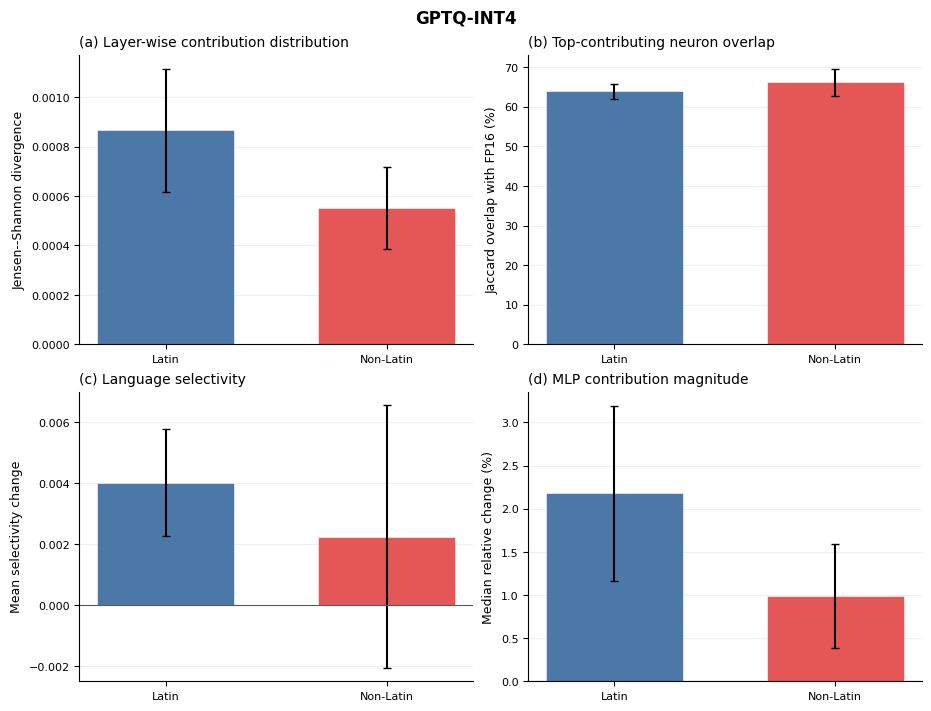

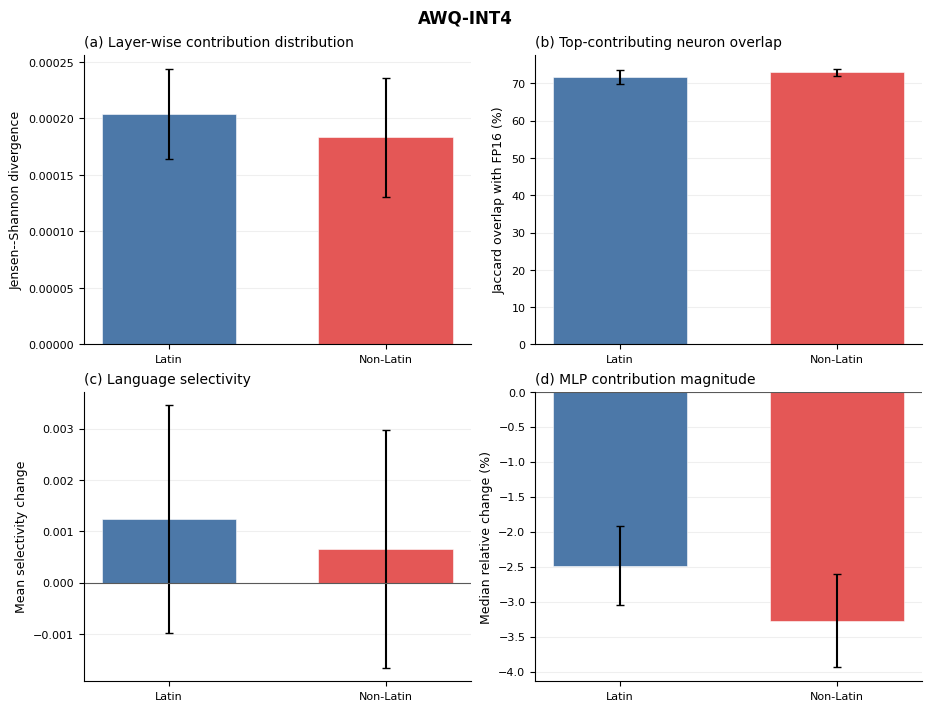

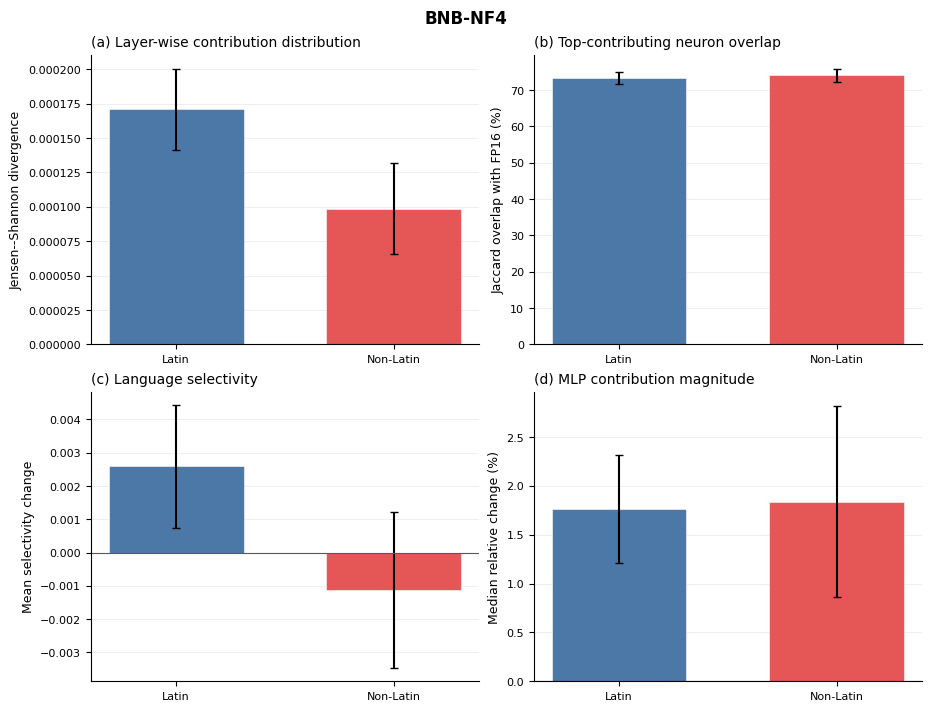

In [16]:
# One appendix figure per quantizer so method-specific scales remain visible.
SCRIPT_GROUP_ORDER = ['Latin', 'Non-Latin']
SCRIPT_GROUP_COLORS = {'Latin': '#4C78A8', 'Non-Latin': '#E45756'}


def grouped_script_bars(
    axis, model_name, metric, ylabel, title, scale=1.0, zero_line=False,
):
    subset = SCRIPT_GROUP_SUMMARY_DF[
        SCRIPT_GROUP_SUMMARY_DF.metric.eq(metric)
        & SCRIPT_GROUP_SUMMARY_DF.model.eq(model_name)
    ]
    x = np.arange(len(SCRIPT_GROUP_ORDER))
    rows = subset.set_index('script_group').reindex(SCRIPT_GROUP_ORDER)
    errors = rows['std'].fillna(0).to_numpy(float) * scale
    axis.bar(
        x,
        rows['mean'].to_numpy(float) * scale,
        width=0.62,
        yerr=errors,
        color=[SCRIPT_GROUP_COLORS[group] for group in SCRIPT_GROUP_ORDER],
        capsize=3,
        edgecolor='white',
        linewidth=0.4,
    )
    if zero_line:
        axis.axhline(0, color='0.35', linewidth=0.8)
    axis.set_xticks(x, SCRIPT_GROUP_ORDER)
    axis.set_ylabel(ylabel)
    axis.set_title(title, loc='left')
    axis.grid(axis='y', alpha=0.2)
    axis.set_axisbelow(True)
    axis.spines[['top', 'right']].set_visible(False)


for model_name in QUANT_METHODS:
    fig, axes = plt.subplots(
        2, 2, figsize=(9.2, 7.0), constrained_layout=True
    )
    grouped_script_bars(
        axes[0, 0], model_name,
        'layer_distribution_jsd',
        'Jensen--Shannon divergence',
        '(a) Layer-wise contribution distribution',
    )
    grouped_script_bars(
        axes[0, 1], model_name,
        'active_neuron_jaccard',
        'Jaccard overlap with FP16 (%)',
        '(b) Top-contributing neuron overlap',
        scale=100.0,
    )
    grouped_script_bars(
        axes[1, 0], model_name,
        'selectivity_delta',
        'Mean selectivity change',
        '(c) Language selectivity',
        zero_line=True,
    )
    grouped_script_bars(
        axes[1, 1], model_name,
        'relative_mlp_contribution_change',
        'Median relative change (%)',
        '(d) MLP contribution magnitude',
        scale=100.0,
        zero_line=True,
    )
    fig.suptitle(model_name, fontsize=12, fontweight='bold')
    method_stem = model_name.lower().replace('-', '_')
    figure_stem = (
        PROPERTY_DIR
        / f'{method_stem}_functional_neuron_property_changes_by_script'
    )
    fig.savefig(figure_stem.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(
        figure_stem.with_suffix('.png'), dpi=300, bbox_inches='tight'
    )
    plt.show()


## 10. Paper-facing analysis: FP16 populations and quantization-induced changes

This section produces the requested appendix analyses directly:

1. the layer-wise FP16 distribution of **language-specific (LAPE)** and
   **transfer** neurons for every language;
2. exact pairwise cross-language overlap values for the two populations,
   reported separately;
3. quantization-induced changes in activation magnitude and MLP contribution
   magnitude at the same special-neuron coordinates; and
4. activation-sign reversals.

In all line plots, Latin-script languages/groups use solid lines and
non-Latin-script languages/groups use dashed lines. Magnitude changes alone do
not capture a neuron whose average activation reverses direction. We therefore
also report a mean-sign flip, but only when the normalized signed activation
$|\mathbb{E}[z]|/\mathbb{E}[|z|]$ is at least 0.1 in both FP16 and the quantized
model. This stability rule prevents near-zero means from being counted as
meaningful sign reversals.


Language-specific neuron counts: 13 languages × all decoder layers


layer,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
language,,,,,,,,,,,,,,,,,,,,,
ca,64,32,4,127,24,7,4,1,9,14,...,86,111,256,393,749,1173,1645,1998,1674,492
en,4,5,3,3,5,2,6,4,3,5,...,6,5,7,12,15,22,21,62,133,177
es,46,23,4,105,23,5,5,1,8,13,...,68,90,212,271,488,606,913,1099,951,363
fr,50,15,2,102,28,3,6,2,9,17,...,96,144,279,320,561,801,1034,1171,1161,401
hu,86,21,5,87,15,15,11,6,8,22,...,105,208,467,551,1013,1349,1744,2136,1679,568
nl,57,20,2,107,20,9,4,2,6,19,...,98,159,305,429,749,1152,1622,1779,1649,562
tr,183,29,11,102,13,18,9,6,9,23,...,118,108,446,590,962,1237,1525,1680,1621,746
ar,550,12,12,109,32,21,13,5,14,30,...,92,91,149,382,680,930,1315,1355,1237,923
el,437,12,8,96,22,16,8,5,8,16,...,84,90,296,352,594,679,900,1221,1719,1312


Transfer-neuron counts: 12 target languages × layers 0–7


layer,0,1,2,3,4,5,6,7
language,,,,,,,,
ca,151,103,90,69,148,152,100,232
es,161,94,79,65,106,150,100,210
fr,168,98,93,64,122,152,105,213
hu,171,116,109,72,171,176,107,243
nl,159,92,85,61,129,139,110,234
tr,167,110,90,65,155,173,111,245
ar,174,89,97,75,153,175,118,238
el,177,98,106,79,142,166,119,233
he,199,121,127,104,177,195,115,233


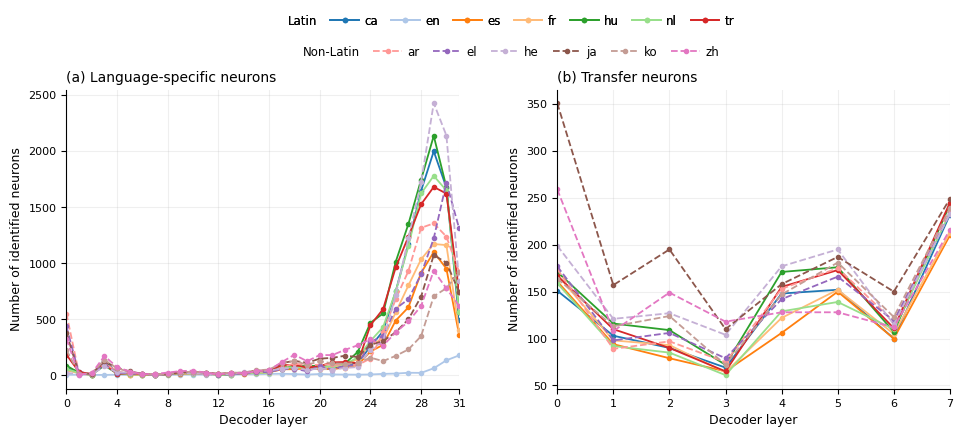

In [17]:
# 10.1 FP16 layer-wise population distributions
# LAPE is identified over all 32 decoder layers and all 13 languages.
# Transfer neurons are defined only for the 12 non-English Tatoeba targets
# and candidate layers 0–7, so the two panels intentionally have different scopes.
lape_distribution_rows = [
    {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
        'layer': layer,
        'population': 'language_specific',
        'neuron_n': len(layer_indices(lape_df, language, layer)),
    }
    for language in LANGUAGES
    for layer in LAPE_ANALYSIS_LAYERS
]
transfer_distribution_rows = [
    {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
        'layer': layer,
        'population': 'transfer',
        'neuron_n': len(PAPER_MASKS[language][layer]),
    }
    for language in TARGET_LANGUAGES
    for layer in RECOVERY_LAYERS
]
FP16_LAYER_DISTRIBUTION_DF = pd.DataFrame(
    lape_distribution_rows + transfer_distribution_rows
)
FP16_LAYER_DISTRIBUTION_DF.to_csv(
    PROPERTY_DIR / 'fp16_language_layer_neuron_distribution.csv',
    index=False,
)

# Explicit language-by-layer count matrices. Each row is one language,
# each column is one decoder layer, and each value is a neuron count.
LAPE_LAYER_COUNT_TABLE = (
    FP16_LAYER_DISTRIBUTION_DF[
        FP16_LAYER_DISTRIBUTION_DF.population.eq('language_specific')
    ]
    .pivot(index='language', columns='layer', values='neuron_n')
    .reindex(index=LANGUAGES, columns=LAPE_ANALYSIS_LAYERS, fill_value=0)
    .fillna(0).astype(int)
)
TRANSFER_LAYER_COUNT_TABLE = (
    FP16_LAYER_DISTRIBUTION_DF[
        FP16_LAYER_DISTRIBUTION_DF.population.eq('transfer')
    ]
    .pivot(index='language', columns='layer', values='neuron_n')
    .reindex(index=TARGET_LANGUAGES, columns=RECOVERY_LAYERS, fill_value=0)
    .fillna(0).astype(int)
)
print('Language-specific neuron counts: 13 languages × all decoder layers')
display(LAPE_LAYER_COUNT_TABLE)
print('Transfer-neuron counts: 12 target languages × layers 0–7')
display(TRANSFER_LAYER_COUNT_TABLE)

language_colors = {
    language: plt.get_cmap('tab20')(index)
    for index, language in enumerate(LANGUAGES)
}
# One line per available language. The panels use independent y-axes because
# the two neuron populations can have substantially different count ranges.
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.4), sharey=False)
fig.subplots_adjust(top=0.79, wspace=0.25)
for axis, population, title in [
    (axes[0], 'language_specific', '(a) Language-specific neurons'),
    (axes[1], 'transfer', '(b) Transfer neurons'),
]:
    if population == 'language_specific':
        count_table = LAPE_LAYER_COUNT_TABLE
        panel_languages = LANGUAGES
    else:
        count_table = TRANSFER_LAYER_COUNT_TABLE
        panel_languages = TARGET_LANGUAGES
    for language in panel_languages:
        layer_counts = count_table.loc[language]
        group = LANGUAGE_SCRIPT_GROUPS[language]
        axis.plot(
            layer_counts.index.to_numpy(), layer_counts.to_numpy(),
            color=language_colors[language],
            linestyle='-' if group == 'Latin' else '--',
            marker='o', markersize=3, linewidth=1.3,
            label=language,
        )
    if population == 'language_specific':
        axis.set_xticks([0, 4, 8, 12, 16, 20, 24, 28, 31])
        axis.set_xlim(0, max(LAPE_ANALYSIS_LAYERS))
    else:
        axis.set_xticks(RECOVERY_LAYERS)
        axis.set_xlim(min(RECOVERY_LAYERS), max(RECOVERY_LAYERS))
    axis.set_xlabel('Decoder layer')
    axis.set_title(title, loc='left')
    axis.grid(alpha=0.2)
    axis.spines[['top', 'right']].set_visible(False)
for axis in axes:
    axis.set_ylabel('Number of identified neurons')
# Two horizontal legend rows above the panels.
from matplotlib.lines import Line2D
handles, labels = axes[0].get_legend_handles_labels()
handle_by_language = dict(zip(labels, handles))
latin_languages = [
    language for language in LANGUAGES
    if LANGUAGE_SCRIPT_GROUPS[language] == 'Latin'
]
non_latin_languages = [
    language for language in LANGUAGES
    if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin'
]
group_label_handle = Line2D([], [], color='none', linestyle='none')
latin_legend = fig.legend(
    [group_label_handle] + [handle_by_language[x] for x in latin_languages],
    ['Latin'] + latin_languages,
    loc='upper center', bbox_to_anchor=(0.5, 0.985),
    frameon=False, ncol=len(latin_languages) + 1, fontsize=8.5,
    handlelength=2.4, columnspacing=1.15, handletextpad=0.45,
)
fig.add_artist(latin_legend)
fig.legend(
    [group_label_handle] + [handle_by_language[x] for x in non_latin_languages],
    ['Non-Latin'] + non_latin_languages,
    loc='upper center', bbox_to_anchor=(0.5, 0.915),
    frameon=False, ncol=len(non_latin_languages) + 1, fontsize=8.5,
    handlelength=2.4, columnspacing=1.15, handletextpad=0.45,
)
stem = PROPERTY_DIR / 'fp16_layerwise_neuron_distribution_by_language'
fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()


In [20]:
PROPERTY_DIR

PosixPath('/root/autodl-tmp/analysis/klar_three_method_lape_transfer_two_discordance_groups/functional_neuron_properties')

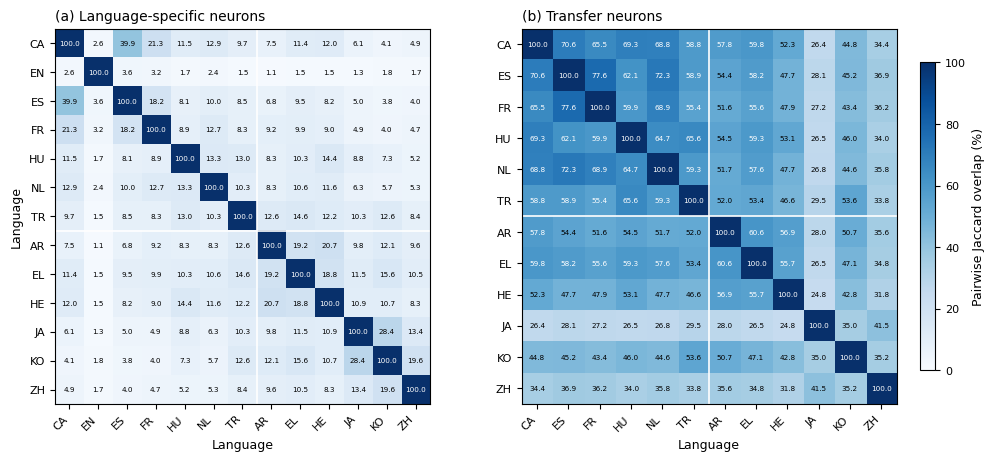

In [18]:
# 10.2 Exact pairwise cross-language overlap, separately by population
full_lape_sets = {
    language: {
        (layer, int(neuron))
        for layer in LAPE_ANALYSIS_LAYERS
        for neuron in layer_indices(lape_df, language, layer).tolist()
    }
    for language in LANGUAGES
}
overlap_value_rows = []
for population, language_sets in [
    ('language_specific', full_lape_sets),
    ('transfer', transfer_sets),
]:
    languages = LANGUAGES if population == 'language_specific' else TARGET_LANGUAGES
    for left_language in languages:
        for right_language in languages:
            left = language_sets[left_language]
            right = language_sets[right_language]
            intersection = left & right
            union = left | right
            overlap_value_rows.append({
                'population': population,
                'left_language': left_language,
                'left_script_group': LANGUAGE_SCRIPT_GROUPS[left_language],
                'right_language': right_language,
                'right_script_group': LANGUAGE_SCRIPT_GROUPS[right_language],
                'left_n': len(left),
                'right_n': len(right),
                'intersection_n': len(intersection),
                'union_n': len(union),
                'jaccard': len(intersection) / len(union) if union else np.nan,
                'overlap_coefficient': (
                    len(intersection) / min(len(left), len(right))
                    if left and right else np.nan
                ),
            })

PAIRWISE_OVERLAP_VALUES_DF = pd.DataFrame(overlap_value_rows)
PAIRWISE_OVERLAP_VALUES_DF.to_csv(
    PROPERTY_DIR / 'fp16_pairwise_language_overlap_values.csv',
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.5), constrained_layout=True)
for axis, population, title in [
    (axes[0], 'language_specific', '(a) Language-specific neurons'),
    (axes[1], 'transfer', '(b) Transfer neurons'),
]:
    languages = LANGUAGES if population == 'language_specific' else TARGET_LANGUAGES
    matrix = (
        PAIRWISE_OVERLAP_VALUES_DF[
            PAIRWISE_OVERLAP_VALUES_DF.population.eq(population)
        ]
        .pivot(index='left_language', columns='right_language', values='jaccard')
        .reindex(index=languages, columns=languages)
    )
    values = 100 * matrix.to_numpy(float)
    image = axis.imshow(
        values, cmap='Blues', vmin=0, vmax=100,
        aspect='equal', interpolation='nearest',
    )
    for row in range(len(languages)):
        for column in range(len(languages)):
            value = values[row, column]
            color = 'white' if value >= 55 else 'black'
            axis.text(
                column, row, f'{value:.1f}',
                ha='center', va='center', fontsize=5.2, color=color,
            )
    axis.set_xticks(
        range(len(languages)),
        [language.upper() for language in languages],
        rotation=45, ha='right',
    )
    axis.set_yticks(
        range(len(languages)),
        [language.upper() for language in languages],
    )
    boundary = sum(LANGUAGE_SCRIPT_GROUPS[language] == 'Latin' for language in languages) - 0.5
    axis.axhline(boundary, color='white', linewidth=1.2)
    axis.axvline(boundary, color='white', linewidth=1.2)
    axis.set_title(title, loc='left')
    axis.set_xlabel('Language')
axes[0].set_ylabel('Language')
colorbar = fig.colorbar(image, ax=axes, shrink=0.82, pad=0.025)
colorbar.set_label('Pairwise Jaccard overlap (%)')
stem = PROPERTY_DIR / 'fp16_pairwise_language_overlap_annotated'
fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()


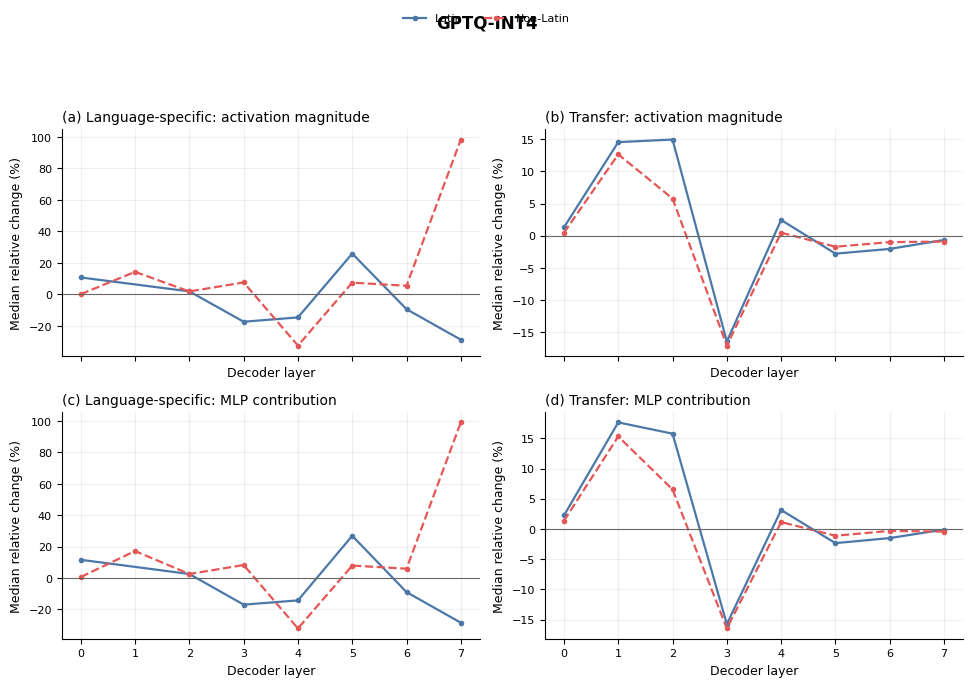

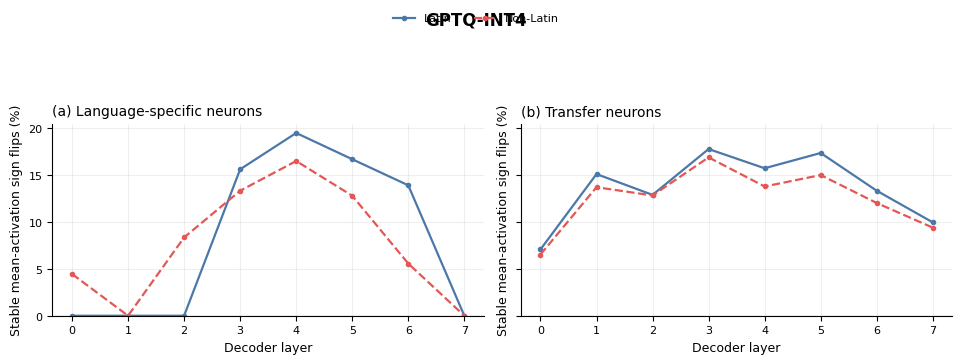

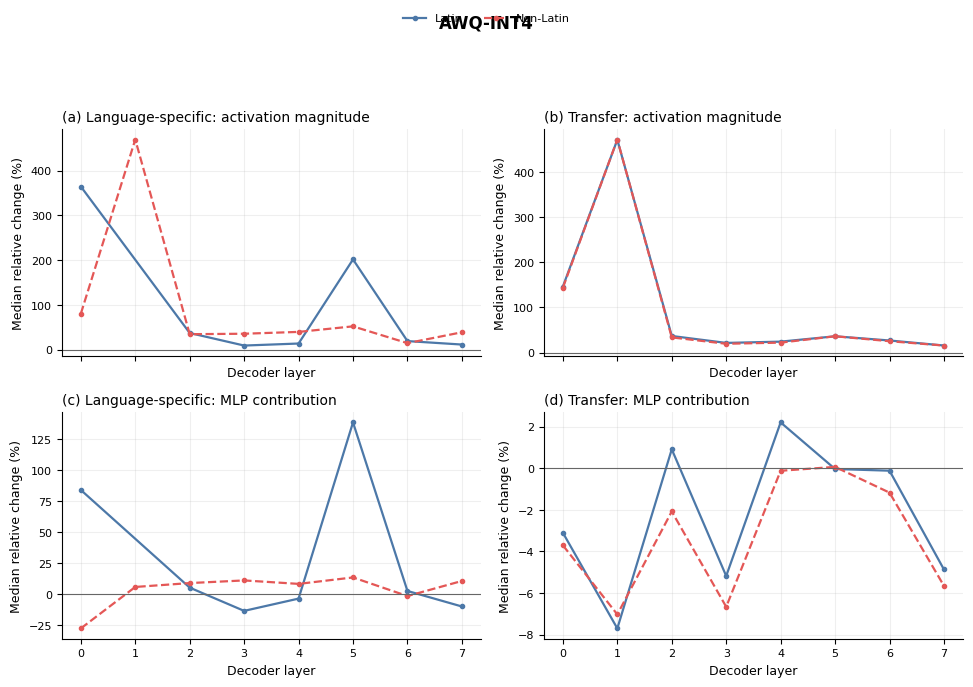

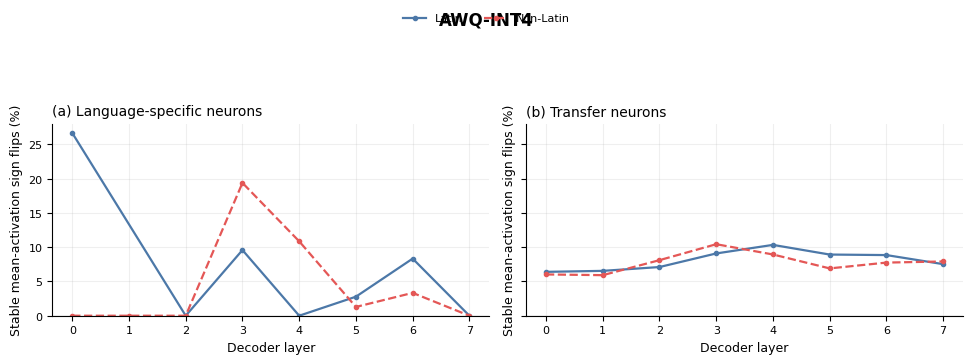

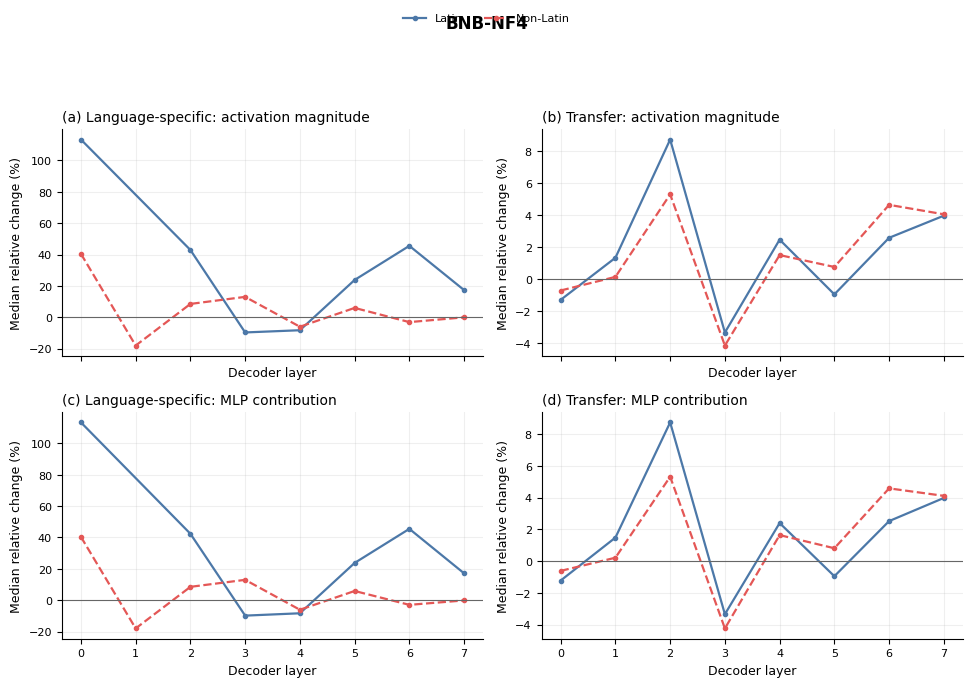

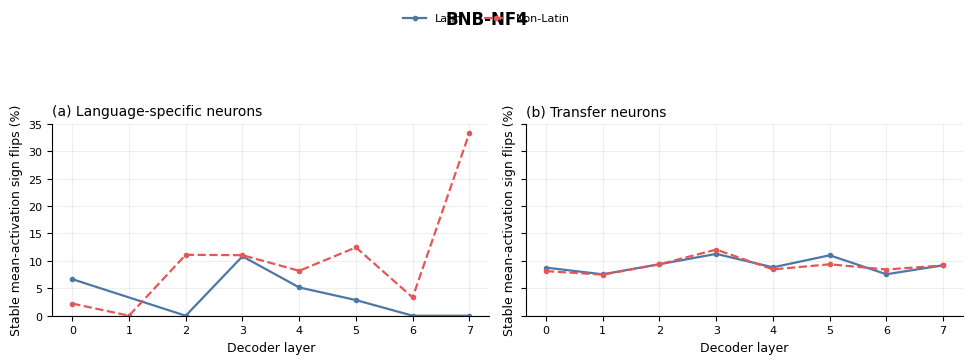

,model,script_group,population,layer,activation_change_mean,activation_change_std,contribution_change_mean,contribution_change_std,sign_flip_rate_mean,sign_flip_rate_std,languages
0,AWQ-INT4,Latin,lape,0,3.645655,5.541402,0.838912,2.179860,0.266667,0.434613,5
1,AWQ-INT4,Latin,lape,2,0.373878,0.972875,0.051798,0.709580,0.000000,0.000000,4
2,AWQ-INT4,Latin,lape,3,0.093686,0.305669,-0.135598,0.244007,0.095833,0.112268,6
3,AWQ-INT4,Latin,lape,4,0.138961,0.394336,-0.036619,0.266871,0.000000,0.000000,6
4,AWQ-INT4,Latin,lape,5,2.017425,2.046798,1.383500,1.696225,0.027778,0.068041,6
...,...,...,...,...,...,...,...,...,...,...,...
136,GPTQ-INT4,Non-Latin,transfer,3,-0.170674,0.019429,-0.164720,0.019466,0.168646,0.042514,6
137,GPTQ-INT4,Non-Latin,transfer,4,0.004710,0.032647,0.011319,0.033801,0.137636,0.014870,6
138,GPTQ-INT4,Non-Latin,transfer,5,-0.017087,0.022491,-0.011265,0.022469,0.149804,0.013465,6
139,GPTQ-INT4,Non-Latin,transfer,6,-0.009919,0.027780,-0.003336,0.027329,0.120045,0.015885,6


In [19]:
# 10.3 Paired activation/contribution changes and stable mean-sign flips
SIGN_STABILITY_THRESHOLD = 0.10
paired_change_frames = []
paired_keys = ['language', 'population', 'layer', 'neuron_index']
fp_population_profiles = (
    POPULATION_PROFILE_DF[POPULATION_PROFILE_DF.model.eq('FP16')]
    [paired_keys + [
        'mean_activation', 'mean_abs_activation',
        'mean_contribution_norm',
    ]]
    .rename(columns={
        'mean_activation': 'fp16_mean_activation',
        'mean_abs_activation': 'fp16_mean_abs_activation',
        'mean_contribution_norm': 'fp16_mean_contribution_norm',
    })
)

for model_name in QUANT_METHODS:
    quant = (
        POPULATION_PROFILE_DF[
            POPULATION_PROFILE_DF.model.eq(model_name)
        ][paired_keys + [
            'mean_activation', 'mean_abs_activation',
            'mean_contribution_norm',
        ]]
        .rename(columns={
            'mean_activation': 'quant_mean_activation',
            'mean_abs_activation': 'quant_mean_abs_activation',
            'mean_contribution_norm': 'quant_mean_contribution_norm',
        })
    )
    paired = quant.merge(
        fp_population_profiles, on=paired_keys, validate='one_to_one'
    )
    paired['model'] = model_name
    paired['script_group'] = paired['language'].map(LANGUAGE_SCRIPT_GROUPS)
    paired['relative_abs_activation_change'] = (
        (paired['quant_mean_abs_activation']
         - paired['fp16_mean_abs_activation'])
        / paired['fp16_mean_abs_activation'].clip(lower=PROPERTY_EPS)
    )
    paired['abs_activation_log2_ratio'] = np.log2(
        (paired['quant_mean_abs_activation'] + PROPERTY_EPS)
        / (paired['fp16_mean_abs_activation'] + PROPERTY_EPS)
    )
    paired['relative_contribution_change'] = (
        (paired['quant_mean_contribution_norm']
         - paired['fp16_mean_contribution_norm'])
        / paired['fp16_mean_contribution_norm'].clip(lower=PROPERTY_EPS)
    )
    paired['contribution_log2_ratio'] = np.log2(
        (paired['quant_mean_contribution_norm'] + PROPERTY_EPS)
        / (paired['fp16_mean_contribution_norm'] + PROPERTY_EPS)
    )

    fp_signedness = (
        paired['fp16_mean_activation']
        / paired['fp16_mean_abs_activation'].clip(lower=PROPERTY_EPS)
    )
    quant_signedness = (
        paired['quant_mean_activation']
        / paired['quant_mean_abs_activation'].clip(lower=PROPERTY_EPS)
    )
    stable = (
        fp_signedness.abs().ge(SIGN_STABILITY_THRESHOLD)
        & quant_signedness.abs().ge(SIGN_STABILITY_THRESHOLD)
    )
    paired['stable_sign_comparison'] = stable
    paired['mean_activation_sign_flip'] = np.where(
        stable,
        np.sign(paired['fp16_mean_activation'])
        != np.sign(paired['quant_mean_activation']),
        np.nan,
    )
    paired_change_frames.append(paired)

SPECIAL_NEURON_CHANGE_DF = pd.concat(
    paired_change_frames, ignore_index=True
)
SPECIAL_NEURON_CHANGE_DF.to_csv(
    PROPERTY_DIR / 'special_neuron_activation_contribution_changes.csv',
    index=False,
)

# Summarize within language first so each language receives equal weight.
SPECIAL_NEURON_LANGUAGE_LAYER_DF = (
    SPECIAL_NEURON_CHANGE_DF.groupby(
        ['model', 'language', 'script_group', 'population', 'layer'],
        as_index=False,
    )
    .agg(
        neuron_n=('neuron_index', 'nunique'),
        median_relative_abs_activation_change=(
            'relative_abs_activation_change', 'median'
        ),
        median_abs_activation_log2_ratio=(
            'abs_activation_log2_ratio', 'median'
        ),
        median_relative_contribution_change=(
            'relative_contribution_change', 'median'
        ),
        median_contribution_log2_ratio=(
            'contribution_log2_ratio', 'median'
        ),
        stable_sign_neuron_n=('stable_sign_comparison', 'sum'),
        mean_activation_sign_flip_rate=(
            'mean_activation_sign_flip', 'mean'
        ),
    )
)
SPECIAL_NEURON_LANGUAGE_LAYER_DF.to_csv(
    PROPERTY_DIR / 'special_neuron_changes_by_language_layer.csv',
    index=False,
)

SPECIAL_NEURON_SCRIPT_LAYER_DF = (
    SPECIAL_NEURON_LANGUAGE_LAYER_DF.groupby(
        ['model', 'script_group', 'population', 'layer'],
        as_index=False,
    )
    .agg(
        activation_change_mean=(
            'median_relative_abs_activation_change', 'mean'
        ),
        activation_change_std=(
            'median_relative_abs_activation_change', 'std'
        ),
        contribution_change_mean=(
            'median_relative_contribution_change', 'mean'
        ),
        contribution_change_std=(
            'median_relative_contribution_change', 'std'
        ),
        sign_flip_rate_mean=('mean_activation_sign_flip_rate', 'mean'),
        sign_flip_rate_std=('mean_activation_sign_flip_rate', 'std'),
        languages=('language', 'nunique'),
    )
)
SPECIAL_NEURON_SCRIPT_LAYER_DF.to_csv(
    PROPERTY_DIR / 'special_neuron_changes_by_script_layer.csv',
    index=False,
)


def plot_change_lines(
    axis, model_name, population, value, title, ylabel, scale=100.0,
):
    subset = SPECIAL_NEURON_SCRIPT_LAYER_DF[
        SPECIAL_NEURON_SCRIPT_LAYER_DF.population.eq(population)
        & SPECIAL_NEURON_SCRIPT_LAYER_DF.model.eq(model_name)
    ]
    for group in ['Latin', 'Non-Latin']:
        rows = subset[subset.script_group.eq(group)].sort_values('layer')
        axis.plot(
            rows['layer'], scale * rows[value],
            color=SCRIPT_GROUP_COLORS[group],
            linestyle='-' if group == 'Latin' else '--',
            marker='o', markersize=3, linewidth=1.6,
            label=group,
        )
    axis.axhline(0, color='0.4', linewidth=0.8)
    axis.set_xticks(RECOVERY_LAYERS)
    axis.set_xlabel('Decoder layer')
    axis.set_ylabel(ylabel)
    axis.set_title(title, loc='left')
    axis.grid(alpha=0.2)
    axis.spines[['top', 'right']].set_visible(False)


for model_name in QUANT_METHODS:
    fig, axes = plt.subplots(2, 2, figsize=(9.8, 6.8), sharex=True)
    plot_change_lines(
        axes[0, 0], model_name, 'lape', 'activation_change_mean',
        '(a) Language-specific: activation magnitude',
        'Median relative change (%)',
    )
    plot_change_lines(
        axes[0, 1], model_name, 'transfer', 'activation_change_mean',
        '(b) Transfer: activation magnitude',
        'Median relative change (%)',
    )
    plot_change_lines(
        axes[1, 0], model_name, 'lape', 'contribution_change_mean',
        '(c) Language-specific: MLP contribution',
        'Median relative change (%)',
    )
    plot_change_lines(
        axes[1, 1], model_name, 'transfer', 'contribution_change_mean',
        '(d) Transfer: MLP contribution',
        'Median relative change (%)',
    )
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.01),
        ncol=2, frameon=False, fontsize=8,
    )
    fig.suptitle(model_name, fontsize=12, fontweight='bold', y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    method_stem = model_name.lower().replace('-', '_')
    stem = (
        PROPERTY_DIR
        / f'{method_stem}_special_neuron_activation_contribution_changes'
    )
    fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Sign-flip rates use a separate method-specific figure.
    fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.5), sharey=True)
    for axis, population, title in [
        (axes[0], 'lape', '(a) Language-specific neurons'),
        (axes[1], 'transfer', '(b) Transfer neurons'),
    ]:
        plot_change_lines(
            axis, model_name, population, 'sign_flip_rate_mean', title,
            'Stable mean-activation sign flips (%)', scale=100.0,
        )
        axis.set_ylim(bottom=0)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04),
        ncol=2, frameon=False, fontsize=8,
    )
    fig.suptitle(model_name, fontsize=12, fontweight='bold', y=1.02)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    stem = PROPERTY_DIR / f'{method_stem}_special_neuron_sign_flips'
    fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show()

display(SPECIAL_NEURON_SCRIPT_LAYER_DF)


### Reporting scope

The four panels quantify property changes for the **same FP16-identified
functional-neuron coordinates**. The count/Jaccard figures in Section 8 describe
the original FP16 population structure; the paired analyses in Section 9 show
how the activity and contribution profiles of those neurons change after
quantization. Recovery accuracy remains a separate causal intervention result.

When reporting these results, use “changes in the properties of FP16-identified
functional neurons.” Do not write that quantization changed LAPE/transfer neuron
identity unless the original discovery procedure is rerun independently on each
quantized model.
